# Введение во временные ряды и обработку сигналов

## Импорты

In [ ]:
# !pip install PyWavelets

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import statsmodels.api as sm

from scipy.signal import (
    find_peaks,
    detrend,
    butter,
    sosfiltfilt,
    welch,
    freqz
)

from scipy.stats import linregress

import pywt

np.random.seed(42)

## Мультипликативная VS аддитивная модель

**Аддитивная модель**:

<center>$Y = Trend + Season + Noise$</center>

**Мультипликативная модель**:
<center>$Y = Trend * Season * Noise$</center>

In [ ]:
sales = np.tile(np.array(1000), 24)

seasonality_m = np.tile(np.array([2, 1.05, 1.1, 0.9]), 6)
seasonality_add = seasonality_m * sales - sales

noise_m = np.random.normal(1, 0.1, len(sales))
noise = noise_m * sales - sales

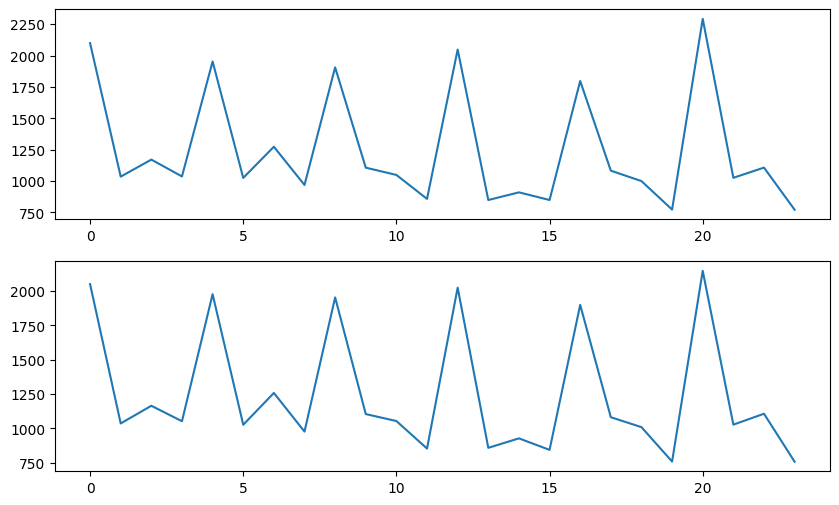

In [ ]:
n_figs = 2
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(sales * seasonality_m * noise_m)
axes[1].plot(sales + seasonality_add + noise)

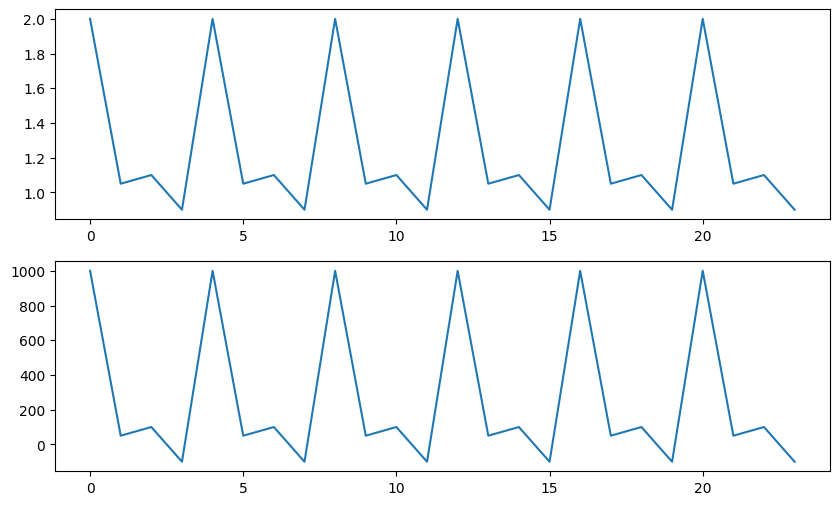

In [ ]:
n_figs = 2
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(seasonality_m)
axes[1].plot(seasonality_add)

In [ ]:
sales = np.arange(1000, 13000, 500)

seasonality_m = np.tile(np.array([2, 1.05, 1.1, 0.9]), 6)
seasonality_add = seasonality_m * sales - sales

noise_m = np.random.normal(1, 0.1, len(sales))
noise = noise_m * sales - sales

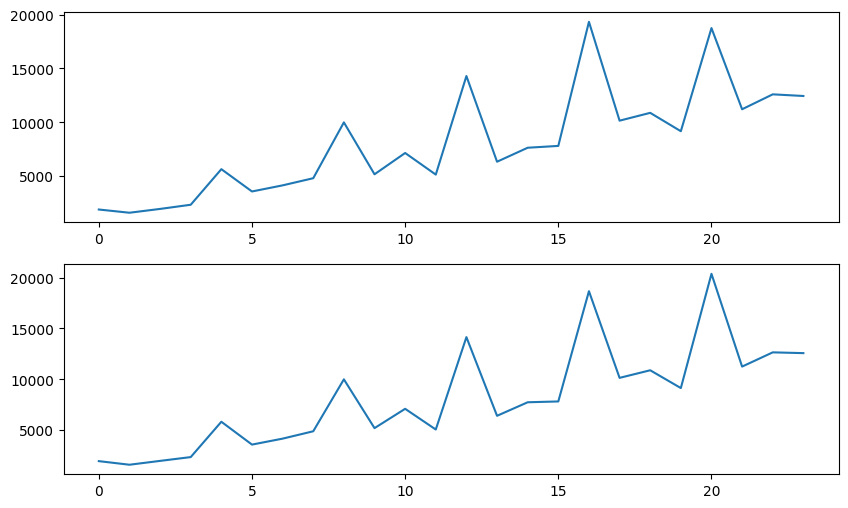

In [ ]:
n_figs = 2
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(sales * seasonality_m * noise_m)
axes[1].plot(sales + seasonality_add + noise)

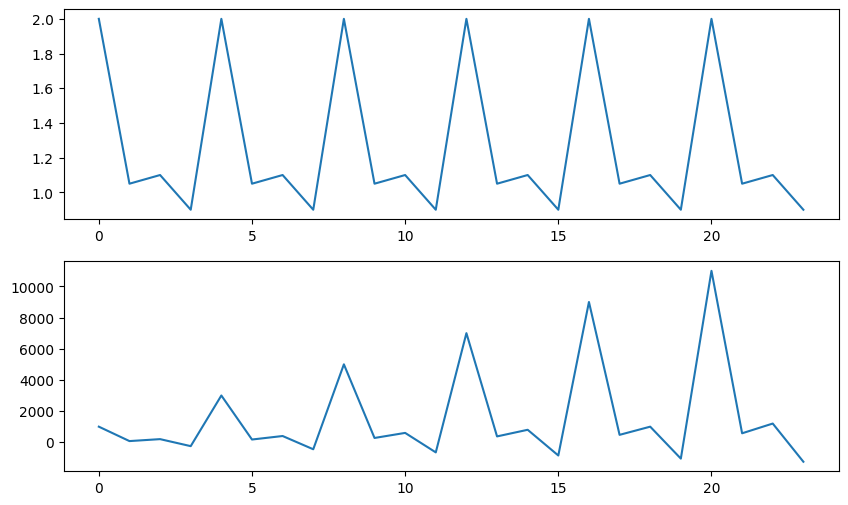

In [ ]:
n_figs = 2
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(seasonality_m)
axes[1].plot(seasonality_add)

**Логарифмирование мультипликативной модели**:
<center>$ln(Y) = ln(Trend) + ln(Season) + ln(Noise)$</center>
<center>$Y = e^{ln(Y)}$</center>

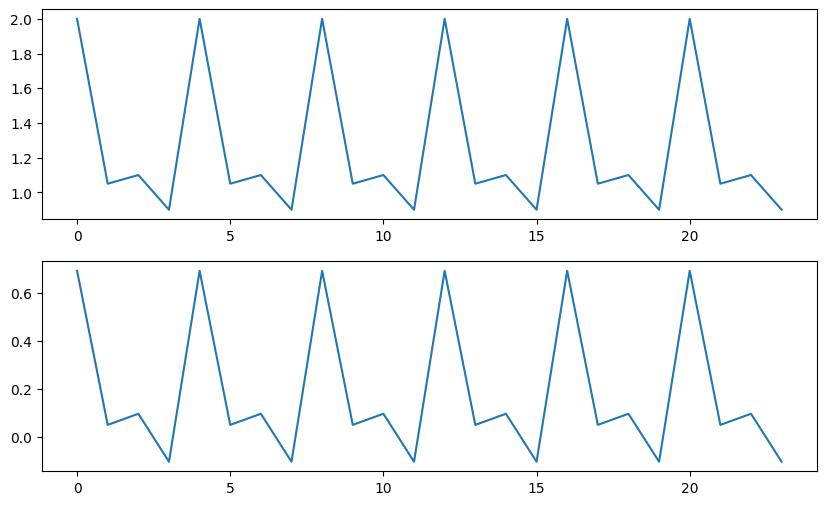

In [ ]:
n_figs = 2
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(seasonality_m)
axes[1].plot(np.log(seasonality_m))

## Разложение временных рядов

In [ ]:
ts = sales + seasonality_add + noise

### seasonal decompose

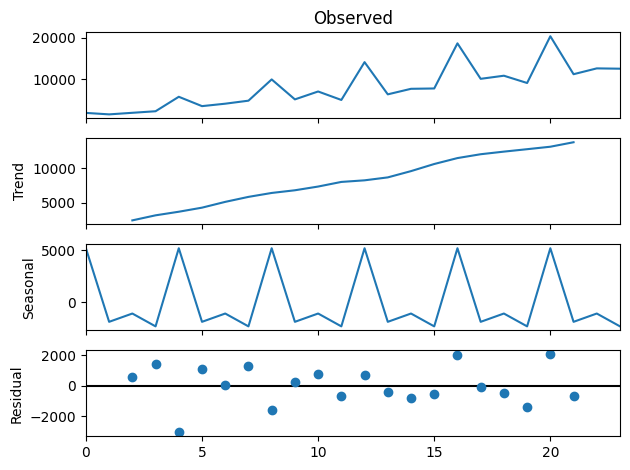

In [ ]:
result = seasonal_decompose(ts,
                            model='additive',
                            period=4  # период сезонности
                            )

result.plot()
plt.show()

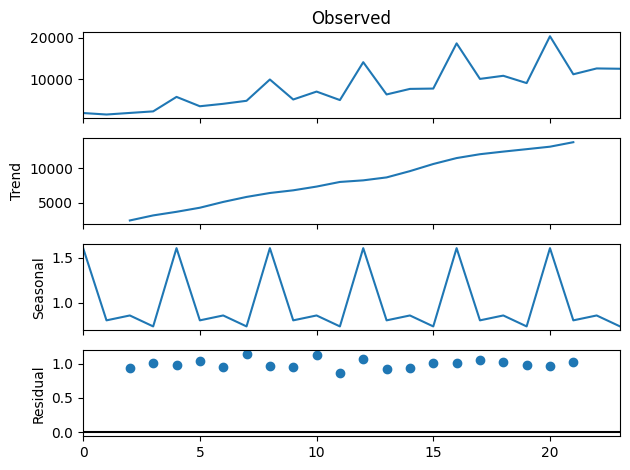

In [ ]:
result = seasonal_decompose(ts,
                            model='multiplicative',  # или 'additive'
                            period=4  # период сезонности
                            )

result.plot()
plt.show()

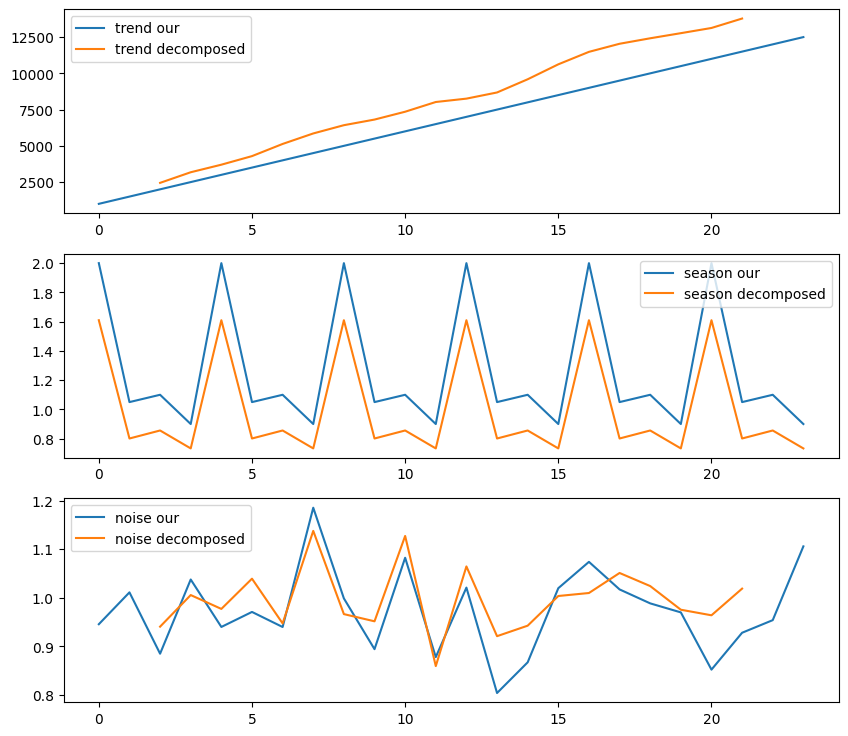

In [ ]:
n_figs = 3
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(sales, label='trend our')
axes[0].plot(result.trend, label='trend decomposed')
axes[1].plot(seasonality_m, label='season our')
axes[1].plot(result.seasonal, label='season decomposed')
axes[2].plot(noise_m, label='noise our')
axes[2].plot(result.resid, label='noise decomposed')
axes[0].legend()
axes[1].legend()
axes[2].legend()

In [ ]:
def estimate_trend(y, period):
    '''
    Используем центрированное скользящее среднее
    '''

    if period % 2 == 0:
        # центрированный фильтр для чётного периода
        weights = np.ones(period + 1) / period
        weights[0] = 0.5 / period
        weights[-1] = 0.5 / period
    else:
        weights = np.ones(period) / period

    # свёртка 2х массивов
    # mode
    ## valid - только положения, где окно полное
    trend = np.convolve(y, weights, mode="valid")

    # Возвращаем результат к исходной длине ряда
    left = (len(y) - len(trend)) // 2
    result = np.full(len(y), np.nan)
    result[left:left + len(trend)] = trend

    return result

def estimate_seasonality(detrended, period, mode='add'):

    # берём все значения на каждом шаге сезонности и усредняем их
    seasonal_pattern = np.array([
        np.nanmean(detrended[j::period])
        for j in range(period)
    ])

    # Находим отклонения - колебания вокруг тренда (центрируем значения)
    if mode == 'add':
      seasonal_pattern -= seasonal_pattern.mean()
    elif mode == 'mult':
      seasonal_pattern /= seasonal_pattern.mean()
    else:
      raise Exception(f'mode is add or mult, but got {mode}')

    # Повторяем сезонный профиль на всю длину ряда
    seasonal = np.tile(
        seasonal_pattern,
        int(np.ceil(len(detrended) / period))
    )[:len(detrended)]

    return seasonal

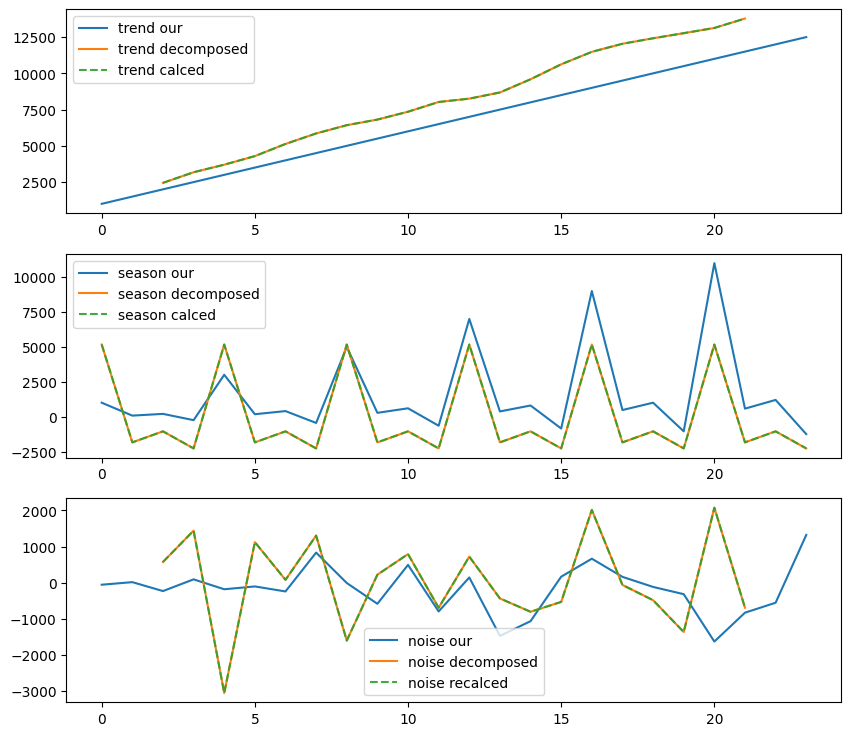

In [ ]:
recalced_trend = estimate_trend(ts, 4)
recalced_season = estimate_seasonality(ts - recalced_trend, 4)

n_figs = 3
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(sales, label='trend our')
axes[0].plot(result.trend, label='trend decomposed')
axes[0].plot(recalced_trend, label="trend calced", ls='--', alpha=0.9)
axes[1].plot(seasonality_add, label='season our')
axes[1].plot(result.seasonal, label='season decomposed')
axes[1].plot(recalced_season, label='season calced', ls='--', alpha=0.9)
axes[2].plot(noise, label='noise our')
axes[2].plot(result.resid, label='noise decomposed')
axes[2].plot(ts - recalced_trend - recalced_season, label='noise recalced', ls='--', alpha=0.9)
axes[0].legend()
axes[1].legend()
axes[2].legend()

### STL (Seasonal-Trend decomposition using Loess)

несколько раз чередует оценку сезонности и тренда с помощью LOESS — локального регрессионного сглаживания

может учитывать меняющуюся во времени сезонность

**LOESS**

В отличие от обычной линейной регрессии на всём ряде, он оценивает зависимость отдельно в окрестности каждого момента времени.

Упрощённо для каждого момента (t):
1. Выбираются ближайшие наблюдения.
2. Близким наблюдениям присваивается больший вес, дальним — меньший.
3. По этим точкам строится локальная регрессия.
4. Значение этой регрессии в точке (t) становится сглаженной оценкой.

С robust=True STL выполняет дополнительные итерации, вычисляя веса по остаткам: наблюдения с необычно большими остатками получают меньший вес при последующем сглаживании.

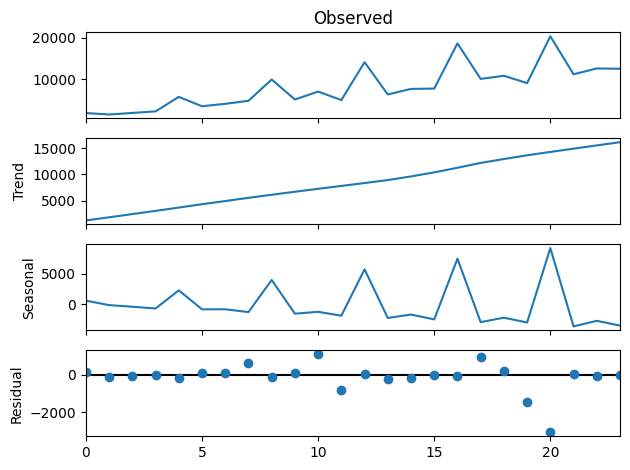

In [ ]:
stl = STL(
    ts,
    period=4,
    seasonal=7,
    robust=True
)

result = stl.fit()
result.plot()
plt.show()

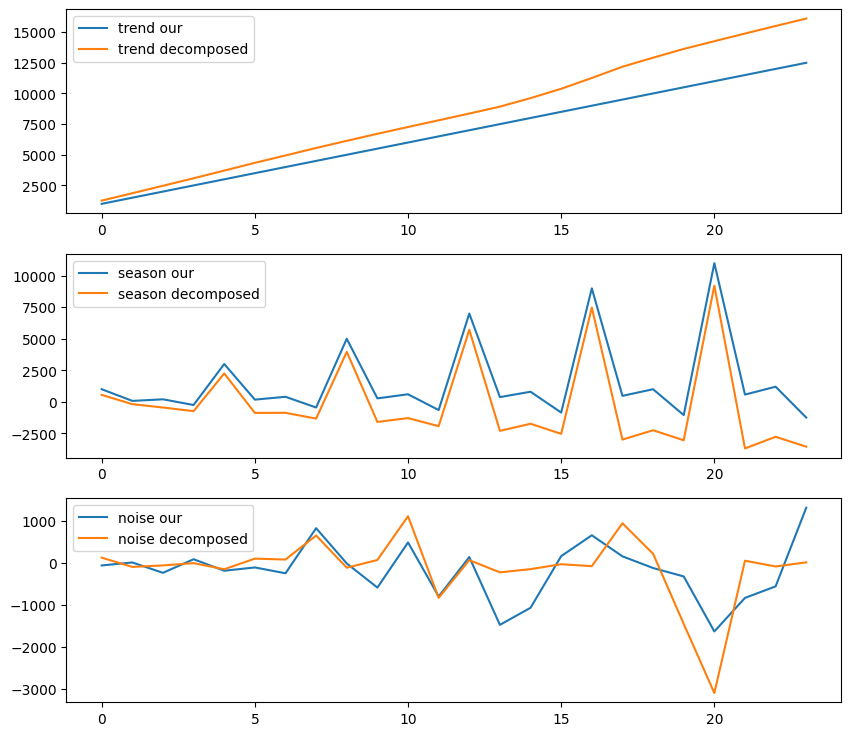

In [ ]:
n_figs = 3
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(sales, label='trend our')
axes[0].plot(result.trend, label='trend decomposed')
axes[1].plot(seasonality_add, label='season our')
axes[1].plot(result.seasonal, label='season decomposed')
axes[2].plot(noise, label='noise our')
axes[2].plot(result.resid, label='noise decomposed')
axes[0].legend()
axes[1].legend()
axes[2].legend()

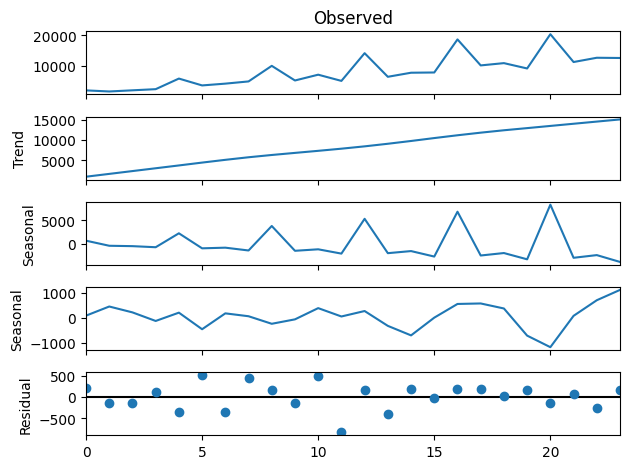

In [ ]:
mstl = MSTL(
    ts,
    periods=[4, 6],
)

result = mstl.fit()
result.plot()
plt.show()

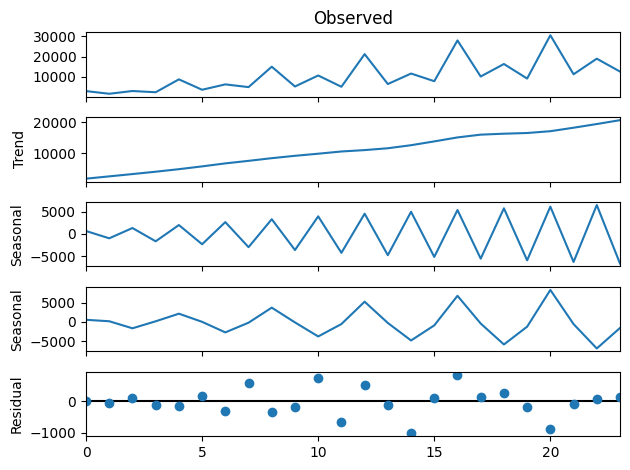

In [ ]:
mstl = MSTL(
    ts * np.tile(np.array([1.5, 1]), 12),
    periods=[2, 4],
)

result = mstl.fit()
result.plot()
plt.show()

### Фурье

Комплексный коэффициент компоненты:
<center>$Y_k =\sum_{n=0}^{N-1}y_ne^{\frac{-i2πkn}{N}}$ (1)</center>

* k - номер проверяемой частоты
* i — мнимая единица, используемая для объединения синуса и косинуса.

Формула Эйлера:<center>$e^{-i\theta}=\cos(\theta)-i\sin(\theta)$</center>

<center>(1) <=> $Y_k =\sum_{n=0}^{N-1}y_n[cos(\frac{2\pi kn}{N})-isin(\frac{2\pi kn}{N})]$</center>

Амплитуда:
<center>$A_k =\frac{2*|Y_k|}{N}$</center>

Формула гармонической регрессии:
<center>$y_t =\beta_0 + \beta_1t+ \sum_{k=1}^{K}[a_ksin(\frac{2\pi kt}{P})+b_kcos(\frac{2\pi kt}{P})] + \epsilon_t$</center>

* P - период сезонности
* k -  номер гармоники
* K - кол-во гармоник
* $a_k, b_k$ - коэффициенты

#### продажи

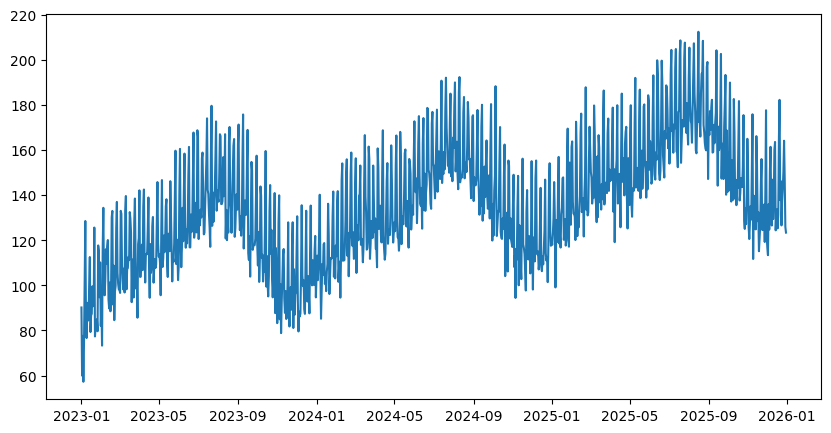

In [ ]:
n = 365 * 3
t = np.arange(n)

# trend
trend_f = 100 + 0.05 * t

# weekly season
day_of_week = t % 7
season_w = np.select(
    [day_of_week == 5, day_of_week == 6],
    [25, 35],
    default=0).astype(float)
# yearly season
season_y =  (20 * np.sin(2 * np.pi * t / 365.25 - np.pi / 2)
    + 10 * np.sin(4 * np.pi * t / 365.25))

# noise
noise = np.random.normal(0, 8, n)

# finally
sales = trend_f + season_w + season_y + noise

plt.figure(figsize=(10,5))
plt.plot(pd.date_range(start="2023-01-01", periods=n), sales)
plt.title("График продаж")
plt.ylabel("кол-во продаж, шт.")

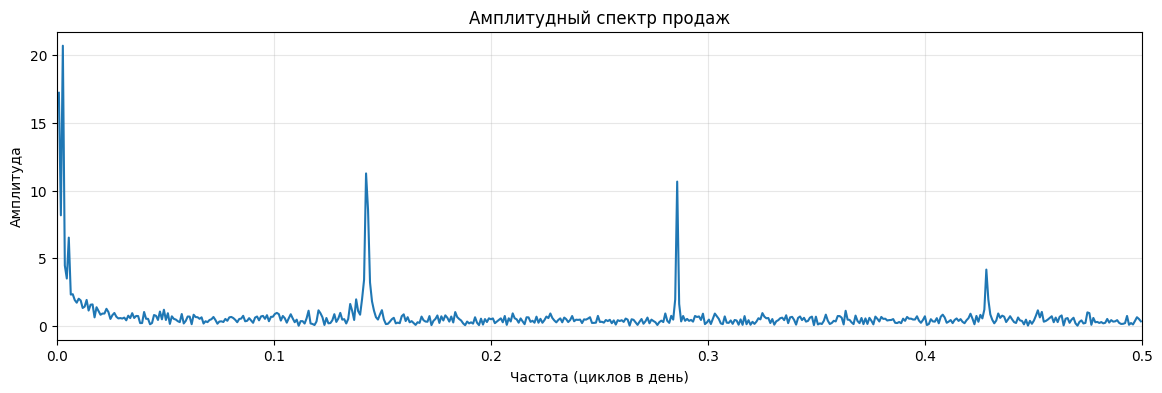

In [ ]:
# получаем комплексный спектр частот
# для каждой частоты сила колебаний (амплитуда) и фаза (угол)
spectrum = np.fft.rfft(sales) #(Real Fast Fourier Transform)

# Частоты в циклах на день
freqs = np.fft.rfftfreq(len(sales), d=1)

# Амплитуды гармоник
amplitude = np.abs(spectrum) / n
# Корректная нормировка одностороннего спектра
if n % 2 == 0:
    amplitude[1:-1] *= 2
else:
    amplitude[1:] *= 2

plt.figure(figsize=(14, 4))
plt.plot(freqs[1:], amplitude[1:])
plt.xlim(0, 0.5)
plt.xlabel("Частота (циклов в день)")
plt.ylabel("Амплитуда")
plt.title("Амплитудный спектр продаж")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
amplitude[0], sales.mean()

(np.float64(135.90652408252691), np.float64(135.9065240825269))

In [ ]:
# частота для недельного периода
1/7

0.14285714285714285

In [ ]:
# частота для годового периода
1/365

0.0027397260273972603

In [ ]:
for period in [7, 365]:
    target_freq = 1 / period
    idx = np.argmin(np.abs(freqs - target_freq))

    print(
        f"""Период: {period} дней
частота: {freqs[idx]:.5f}
index: {idx}
оценка периода: {1 / freqs[idx]:.2f} дней"""
        + "\n"
        + "----- " * 5
    )

Период: 7 дней
частота: 0.14247
index: 156
оценка периода: 7.02 дней
----- ----- ----- ----- ----- 
Период: 365 дней
частота: 0.00274
index: 3
оценка периода: 365.00 дней
----- ----- ----- ----- ----- 


In [ ]:
def harmonic_decompose(y, season_params=dict(), trend_degree=1):
    """
    y — временной ряд с равномерным шагом, например ежедневные продажи.
    Возвращает тренд, недельную и годовую сезонность, остаток.
    season_params: {период: сколько гармоник берём}
    """
    y = np.asarray(y, dtype=float)
    n = len(y)
    t = np.arange(n)

    # Отдельное время для тренда и сезонности
    t_trend = t.copy()

    # Константа и тренд
    features = [t_trend ** degree for degree in range(trend_degree + 1)]
    trend_cols = [i for i in range(trend_degree + 1)]

    # Сохраняем номера столбцов для каждой компоненты
    season_cols = {season: [] for season in season_params.keys()}

    for season_order, harmonics in season_params.items():
        season_cols[season_order] = []
        for k in range(1, harmonics + 1):
            sin_col = len(features)
            features.append(np.sin(2 * np.pi * k * t / season_order))
            cos_col = len(features)
            features.append(np.cos(2 * np.pi * k * t / season_order))
            season_cols[season_order].extend([sin_col, cos_col])

    X = np.column_stack(features)

    # Находим коэффициенты методом наименьших квадратов
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)

    result = dict()
    # Разделяем рассчитанные компоненты
    result['trend'] = X[:, trend_cols] @ coef[trend_cols]
    result['residual'] = y - result['trend']
    for season in season_params.keys():
      result[f'season_{season}'] = X[:, season_cols[season]] @ coef[season_cols[season]]
      result['residual'] -= result[f'season_{season}']

    return result

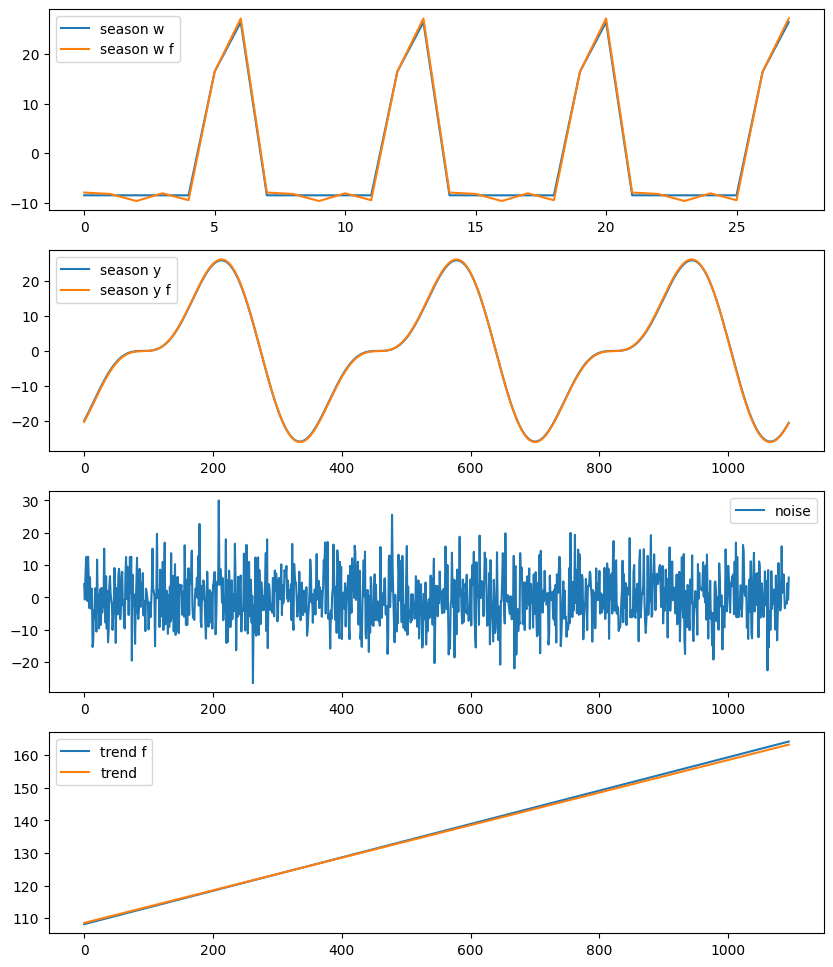

In [ ]:
sales_with_f = harmonic_decompose(sales, {7:3, 365:2})

n_figs = 4
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot((season_w - season_w.mean())[:28], label='season w')
axes[0].plot(sales_with_f['season_7'][:28], label='season w f')
axes[1].plot(season_y - season_y.mean(), label='season y')
axes[1].plot(sales_with_f['season_365'], label='season y f')
axes[2].plot(sales_with_f['residual'], label='noise')
axes[3].plot(sales_with_f['trend'], label='trend f')
axes[3].plot(trend_f + season_w.mean() + season_y.mean(), label='trend')
axes[0].legend()
axes[1].legend()
axes[2].legend()
axes[3].legend()

#### CO2

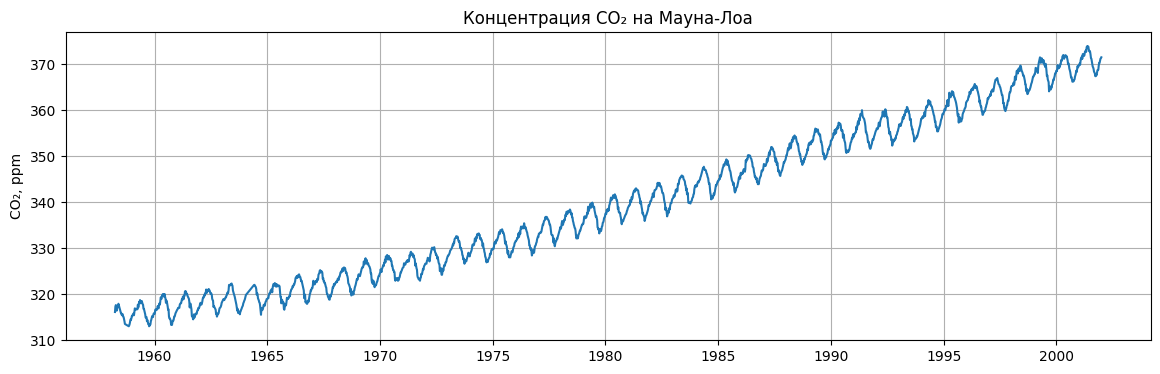

In [ ]:
# Реальные измерения CO2 на Мауна-Лоа
co2 = sm.datasets.co2.load_pandas().data["co2"]

# Переводим в недельный ряд и заполняем пропуски
co2 = co2.resample("W").mean().interpolate("time")

y = co2.to_numpy()
dates = co2.index

plt.figure(figsize=(14, 4))
plt.plot(dates, y)
plt.title("Концентрация CO₂ на Мауна-Лоа")
plt.ylabel("CO₂, ppm")
plt.grid(True)
plt.show()

In [ ]:
spectrum = np.fft.rfft(y)
amplitude = np.abs(spectrum) / n
y.mean(), amplitude[0]

(np.float64(339.6524956217163), np.float64(339.6524956217163))

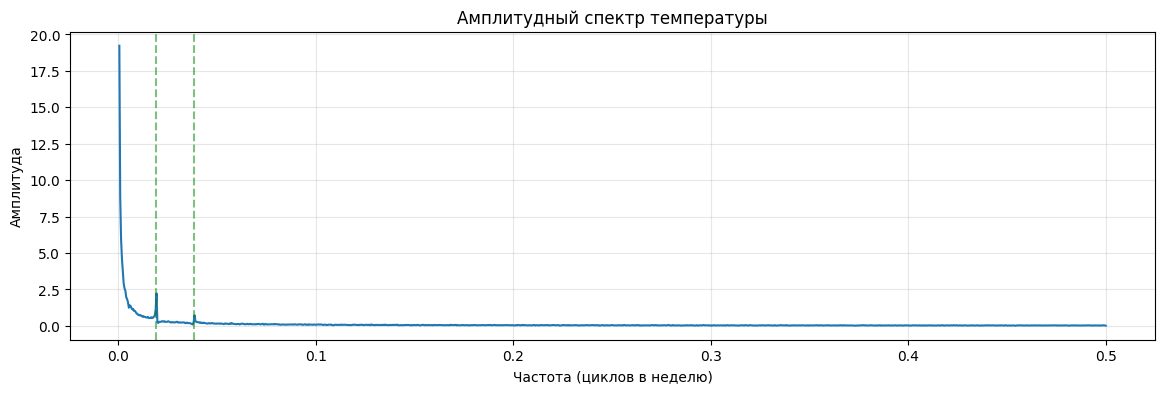

In [ ]:
n = len(y)

spectrum = np.fft.rfft(y - y.mean())

# Частоты в циклах на неделю
freqs = np.fft.rfftfreq(n, d=1)

# Амплитуды гармоник
amplitude = np.abs(spectrum) / n
# Корректная нормировка одностороннего спектра
if n % 2 == 0:
    amplitude[1:-1] *= 2
else:
    amplitude[1:] *= 2

plt.figure(figsize=(14, 4))
plt.plot(freqs[1:], amplitude[1:])
plt.axvline(7 / 365, ls='--', c='g', alpha=.5)
plt.axvline(14 / 365, ls='--', c='g', alpha=.5)
plt.xlabel("Частота (циклов в неделю)")
plt.ylabel("Амплитуда")
plt.title("Амплитудный спектр температуры")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
1 / freqs[1], len(y)

(np.float64(2284.0), 2284)

In [ ]:
365/7, 7/365, 1/52, 2/52, 52/2

(52.142857142857146,
 0.019178082191780823,
 0.019230769230769232,
 0.038461538461538464,
 26.0)

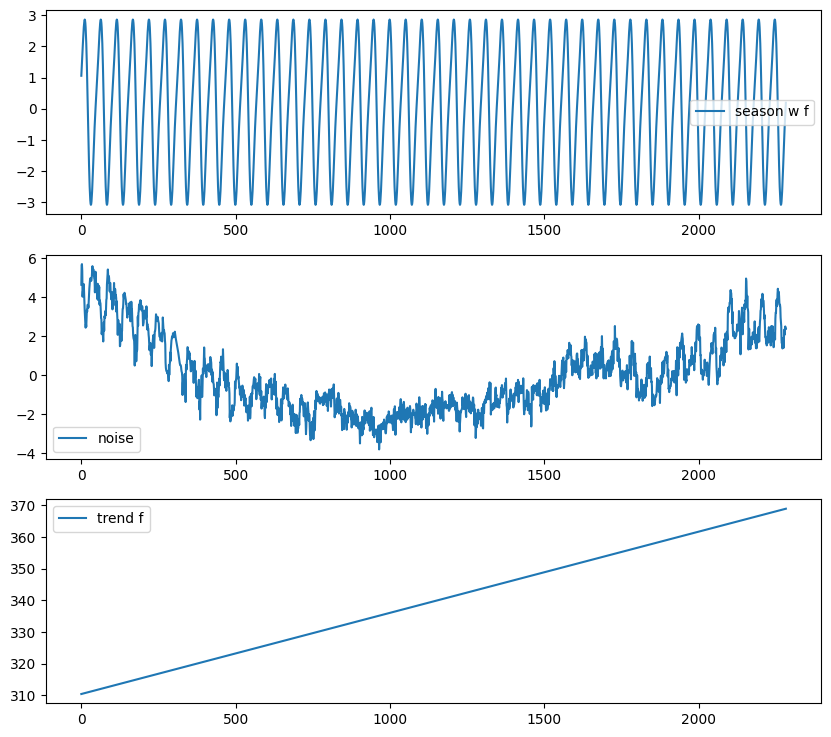

In [ ]:
co2_f_1 = harmonic_decompose(y, {52:2}, trend_degree=1)

n_figs = 3
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(co2_f_1['season_52'], label='season w f')
axes[1].plot(co2_f_1['residual'], label='noise')
axes[2].plot(co2_f_1['trend'], label='trend f')
axes[0].legend()
axes[1].legend()
axes[2].legend()

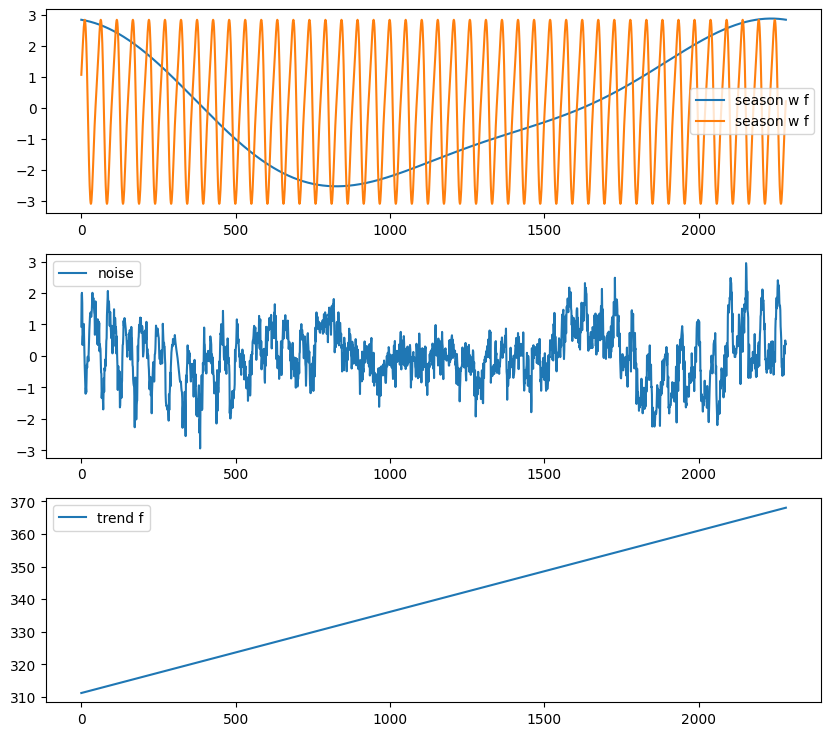

In [ ]:
co2_f_1 = harmonic_decompose(y, {2284: 2, 52:2}, trend_degree=1)

n_figs = 3
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(co2_f_1['season_2284'], label='season w f')
axes[0].plot(co2_f_1['season_52'], label='season w f')
axes[1].plot(co2_f_1['residual'], label='noise')
axes[2].plot(co2_f_1['trend'], label='trend f')
axes[0].legend()
axes[1].legend()
axes[2].legend()

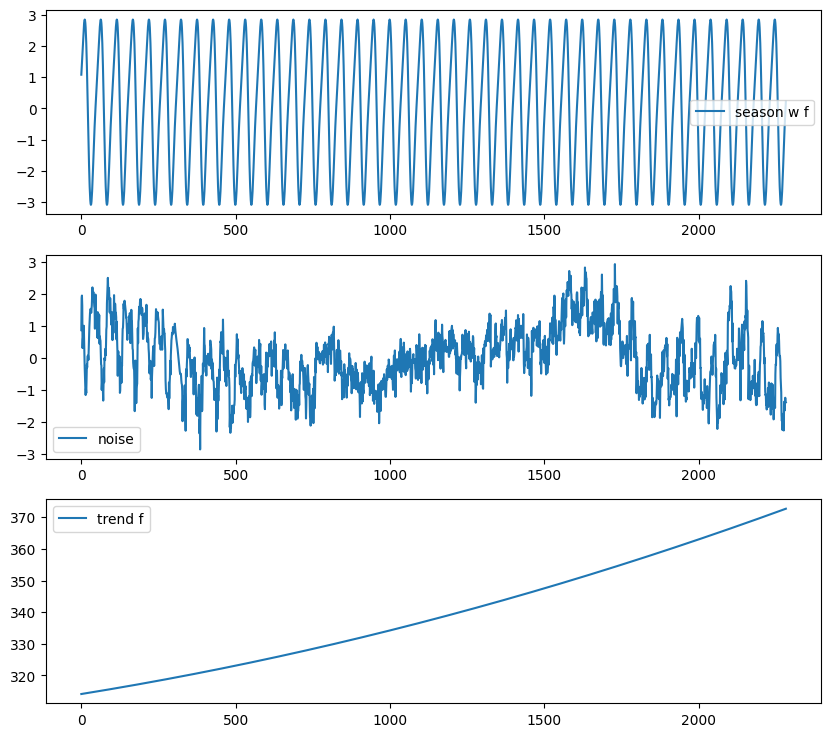

In [ ]:
co2_f_1 = harmonic_decompose(y, {52:2}, trend_degree=2)

n_figs = 3
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(co2_f_1['season_52'], label='season w f')
axes[1].plot(co2_f_1['residual'], label='noise')
axes[2].plot(co2_f_1['trend'], label='trend f')
axes[0].legend()
axes[1].legend()
axes[2].legend()

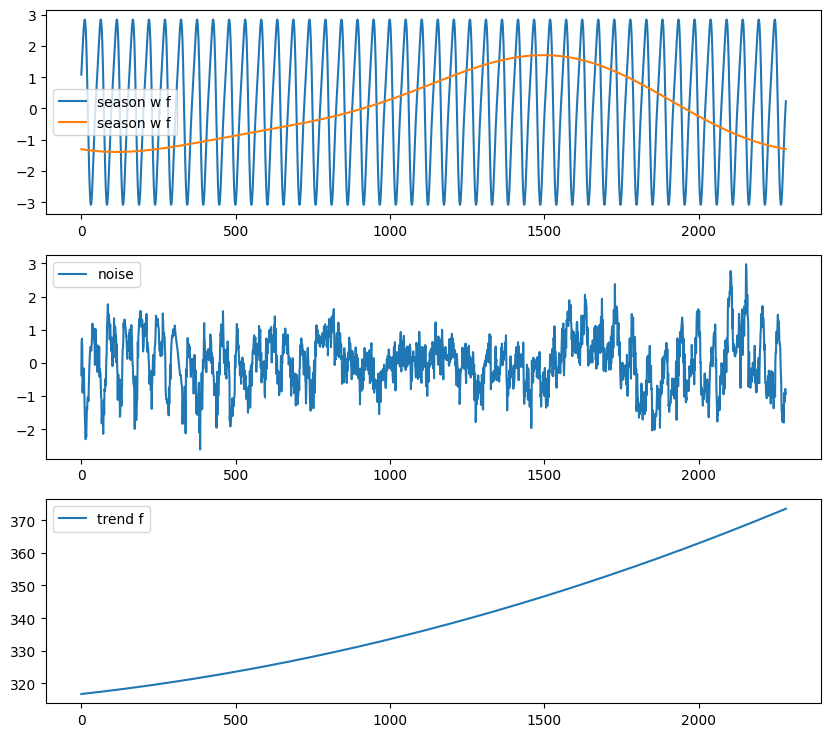

In [ ]:
co2_f_1 = harmonic_decompose(y, {52:2, 2284:2}, trend_degree=2)

n_figs = 3
fig, axes = plt.subplots(n_figs, 1, figsize=(10, 3 * n_figs))
axes[0].plot(co2_f_1['season_52'], label='season w f')
axes[0].plot(co2_f_1['season_2284'], label='season w f')
axes[1].plot(co2_f_1['residual'], label='noise')
axes[2].plot(co2_f_1['trend'], label='trend f')
axes[0].legend()
axes[1].legend()
axes[2].legend()

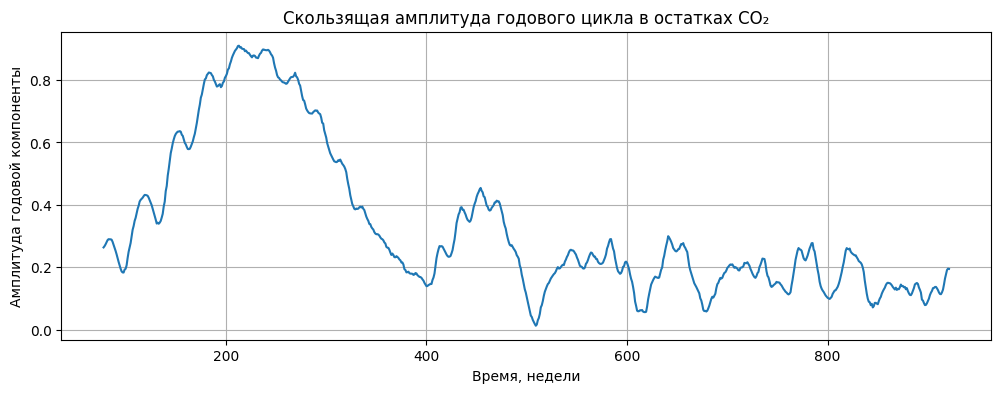

In [ ]:
def rolling_harmonic_amplitude(y, period=52, window=3 * 52):
    y = np.asarray(y, dtype=float)
    t = np.arange(len(y))

    centers = np.arange(window // 2, len(y) - window // 2)
    amplitudes = []

    for center in centers:
        start = center - window // 2
        end = start + window

        tw = t[start:end]
        yw = y[start:end]

        # Локальная линейная компонента + годовые sin/cos
        X = np.column_stack([
            np.ones(len(tw)),
            tw - center,
            np.sin(2 * np.pi * tw / period),
            np.cos(2 * np.pi * tw / period)
        ])

        beta, *_ = np.linalg.lstsq(X, yw, rcond=None)

        # Амплитуда синусоидальной компоненты
        amplitude = np.hypot(beta[2], beta[3])
        amplitudes.append(amplitude)

    return centers, np.asarray(amplitudes)


centers, amplitude = rolling_harmonic_amplitude(
    co2_f_1['residual'],
    period=52,
    window=3 * 52
)

plt.figure(figsize=(12, 4))
plt.plot(centers, amplitude)
plt.xlabel("Время, недели")
plt.ylabel("Амплитуда годовой компоненты")
plt.title("Скользящая амплитуда годового цикла в остатках CO₂")
plt.grid(True)
plt.show()

### Вейвлет-разложение



###  анализ сигнала

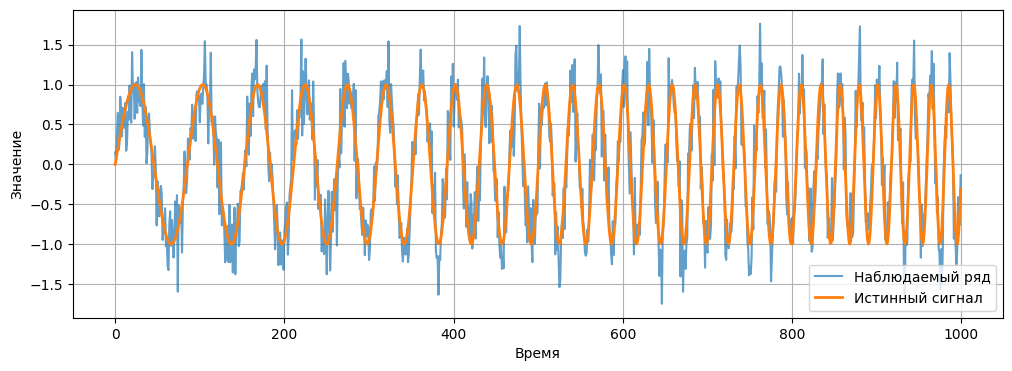

In [ ]:
n = 1000
t = np.arange(n)

# Частота постепенно растёт
phase = 2 * np.pi * (0.01 * t + 0.00002 * t**2)
signal = np.sin(phase)

# Добавляем шум
y = signal + np.random.normal(0, 0.3, n)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t, y, label="Наблюдаемый ряд", alpha=0.7)
ax.plot(t, signal, label="Истинный сигнал", linewidth=2)
ax.set_xlabel("Время")
ax.set_ylabel("Значение")
ax.legend()
ax.grid(True)
plt.show()

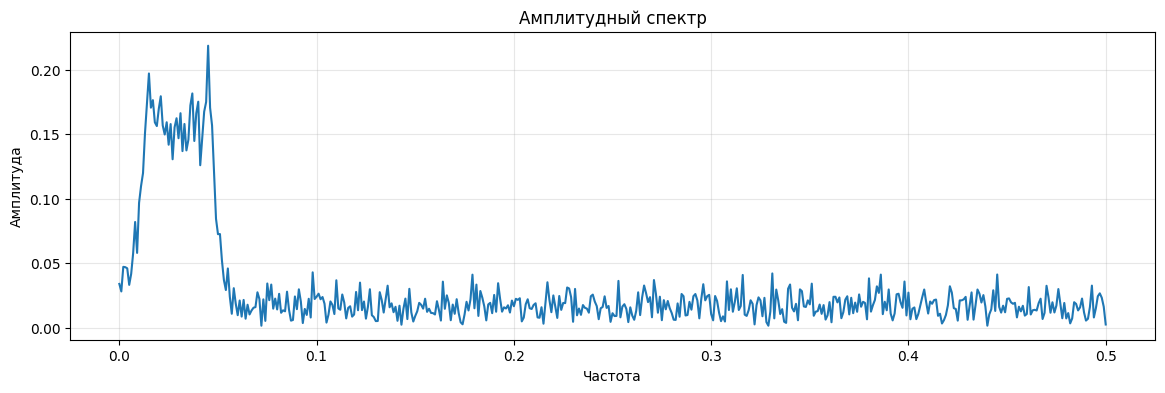

In [ ]:
n = len(y)

spectrum = np.fft.rfft(y)

# Частоты в циклах
freqs = np.fft.rfftfreq(n, d=1)

# Амплитуды гармоник
amplitude = np.abs(spectrum) / n
# Удваиваем внутренние положительные частоты
if n % 2 == 0:
    amplitude[1:-1] *= 2  # последний элемент — частота Найквиста
else:
    amplitude[1:] *= 2

plt.figure(figsize=(14, 4))
plt.plot(freqs, amplitude)
plt.xlabel("Частота")
plt.ylabel("Амплитуда")
plt.title("Амплитудный спектр")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
freq_nonzero = freqs[1:]
amplitude_nonzero = amplitude[1:]

periods = 1 / freq_nonzero

peaks, _ = find_peaks(amplitude_nonzero, distance=3, prominence=0.01)

top = peaks[np.argsort(amplitude_nonzero[peaks])[::-1][:10]]

peaks_periods = []

for i in top:
    print(f"Период: {periods[i]:.1f}, частота {freq_nonzero[i]}, амплитуда: {amplitude_nonzero[i]:.3f}")
    peaks_periods.append(round(periods[i]))
print('---------')
print(sorted(peaks_periods)[:6])
print('---------')
print(sorted(1/x for x in peaks_periods)[:6])

Период: 22.2, частота 0.045, амплитуда: 0.219
Период: 66.7, частота 0.015, амплитуда: 0.197
Период: 27.0, частота 0.037, амплитуда: 0.182
Период: 47.6, частота 0.021, амплитуда: 0.179
Период: 25.0, частота 0.04, амплитуда: 0.175
Период: 32.3, частота 0.031, амплитуда: 0.166
Период: 125.0, частота 0.008, амплитуда: 0.082
Период: 500.0, частота 0.002, амплитуда: 0.047
Период: 18.2, частота 0.055, амплитуда: 0.046
Период: 10.2, частота 0.098, амплитуда: 0.043
---------
[10, 18, 22, 25, 27, 32]
---------
[0.002, 0.008, 0.014925373134328358, 0.020833333333333332, 0.03125, 0.037037037037037035]


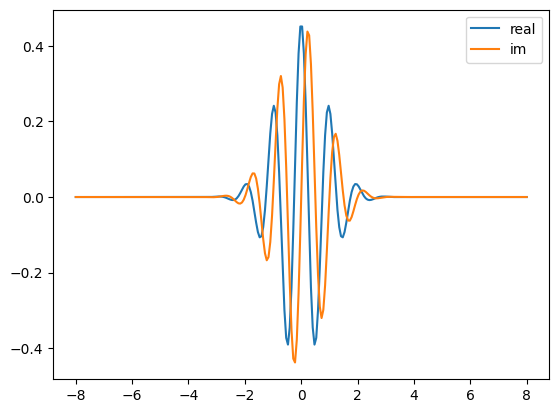

In [ ]:
# ContinuousWavelet - чтобы увидеть, когда возникают колебания определённых периодов
psi, x = pywt.ContinuousWavelet("cmor1.5-1.0").wavefun(level=8)
plt.plot(x, psi.real, label='real')
plt.plot(x, psi.imag, label='im')

plt.legend()
plt.show()

In [ ]:
wavelet = "cmor1.5-1.0"
pywt.central_frequency(wavelet, precision=8)

np.float64(1.0)

Масштаб вейвлета:
<center>$scales = \frac{f_c}{f*\Delta t}$<center>

Мощность:
<center>$P(s,t) = |W(s,t)^2|$</center>

Амплитуда:
<center>$P(s,t) = |W(s,t)|$<center>

100


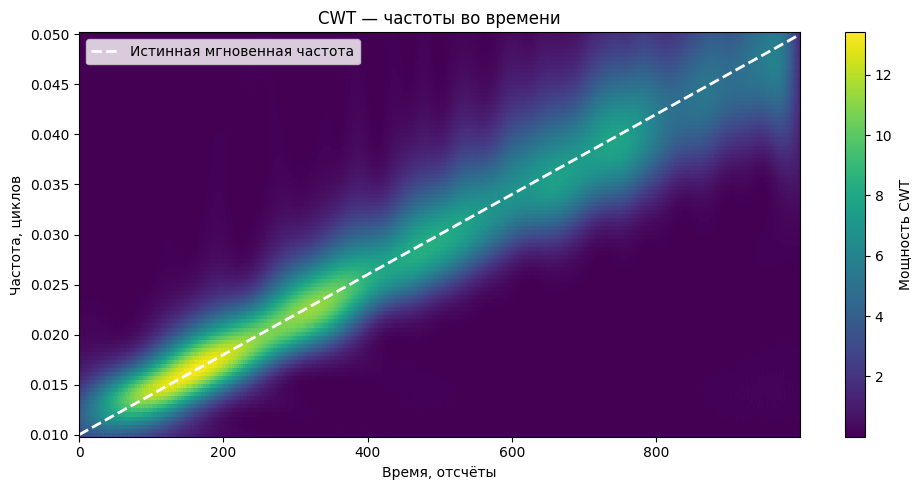

In [ ]:
wavelet = "cmor1.5-1.0"

# Перевод желаемых периодов в масштабы вейвлета
target_freqs = np.linspace(0.01, 0.05, 100)
scales = pywt.frequency2scale(wavelet, target_freqs)

coefficients, cwt_freqs = pywt.cwt(
    y,
    scales,
    wavelet,
    sampling_period=1
)
print(len(coefficients))

power = np.abs(coefficients) ** 2

# Теоретическая мгновенная частота сигнала
instant_freq = 0.01 + 0.00004 * t

# Рисуем сравнение
plt.figure(figsize=(10, 5))

# CWT
mesh = plt.pcolormesh(
    t,
    cwt_freqs,
    power,
    shading="auto",
    cmap="viridis"
)

plt.plot(
    t,
    instant_freq,
    "w--",
    linewidth=2,
    label="Истинная мгновенная частота"
)
plt.title("CWT — частоты во времени")
plt.xlabel("Время, отсчёты")
# plt.yscale('log')
plt.ylabel("Частота, циклов")
# plt.ylim(0, 0.08)
plt.legend()
plt.colorbar(mesh, label="Мощность CWT")

plt.tight_layout()
plt.show()

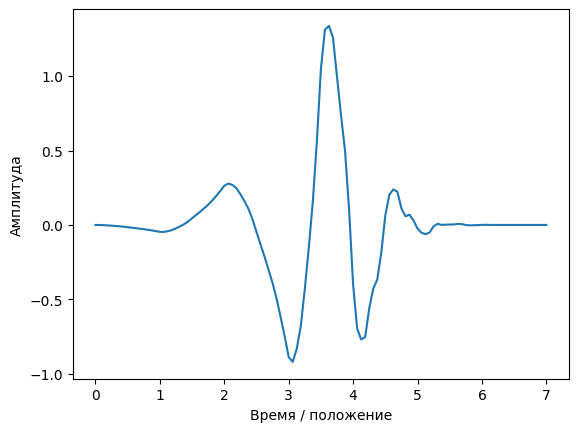

In [ ]:
# дискретный - выделение компонент
phi, psi, x = pywt.Wavelet("db4").wavefun(level=4)
plt.plot(x, psi)
plt.xlabel("Время / положение")
plt.ylabel("Амплитуда")
plt.show()

Кол-во коэффициентов: 5
Длина исходного ряда: 1000
Компонент 0: длина 69
Компонент 1: длина 69
Компонент 2: длина 131
Компонент 3: длина 255
Компонент 4: длина 503


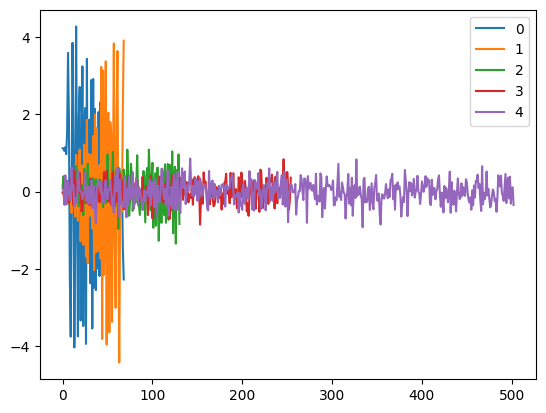

In [ ]:
# Daubechies
wavelet = "db4"
level = 4

# Многоуровневое разложение
# набор коэффициентов разложения по уровням
# сначала последняя аппроксимация (самые быстрые колебания)
coeffs = pywt.wavedec(y, wavelet, level=level, mode="symmetric")

# первая компонента - аппроксимация (cA) (плавная часть)
# с конца до второй - детализация (cD)
print(f'Кол-во коэффициентов: {len(coeffs)}')
print("Длина исходного ряда:", len(y))
for i, c in enumerate(coeffs):
    # L = (N + F - 1) / 2 (округл вниз)
    print(f"Компонент {i}: длина {len(c)}")
    plt.plot(coeffs[i], label=i)
plt.legend()

In [ ]:
# длина фильтра
pywt.Wavelet("db4").dec_len, pywt.Wavelet("db4").rec_len

(8, 8)

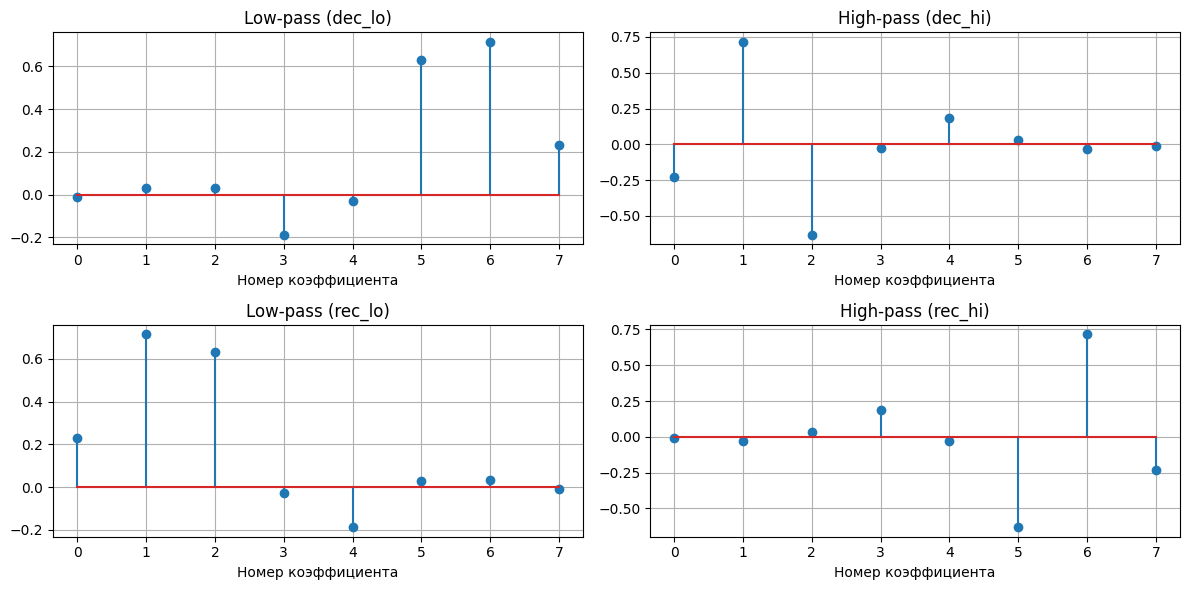

In [ ]:
import matplotlib.pyplot as plt

filters = {
    "Low-pass (dec_lo)": pywt.Wavelet("db4").dec_lo,
    "High-pass (dec_hi)": pywt.Wavelet("db4").dec_hi,
    "Low-pass (rec_lo)": pywt.Wavelet("db4").rec_lo,
    "High-pass (rec_hi)": pywt.Wavelet("db4").rec_hi
}

fig, axes = plt.subplots(2, 2, figsize=(12, 6))

for ax, (name, values) in zip(axes.flat, filters.items()):
    ax.stem(range(len(values)), values)
    ax.set_title(name)
    ax.set_xlabel("Номер коэффициента")
    ax.grid()

plt.tight_layout()
plt.show()

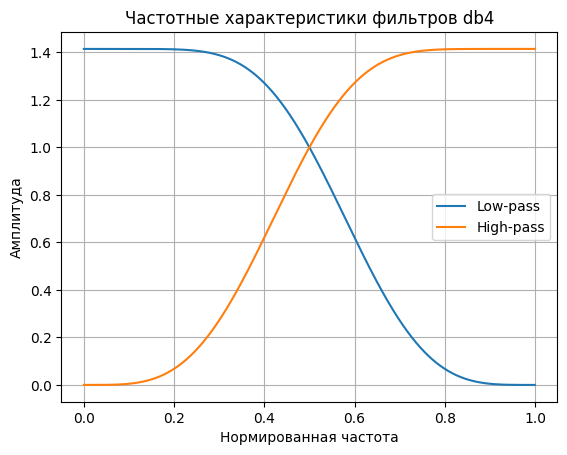

In [ ]:
wavelet = pywt.Wavelet("db4")

for name, filt in [
    ("Low-pass", wavelet.dec_lo),
    ("High-pass", wavelet.dec_hi)
]:
    freq, response = freqz(filt, worN=2048)

    plt.plot(
      freq / np.pi,
      np.abs(response), # амплитуда - насколько усиливает/ослабевает частоту
      label=name
  )

plt.xlabel("Частота")
plt.ylabel("Амплитуда")
plt.title("Частотные характеристики фильтров db4")
plt.legend()
plt.grid()
plt.show()

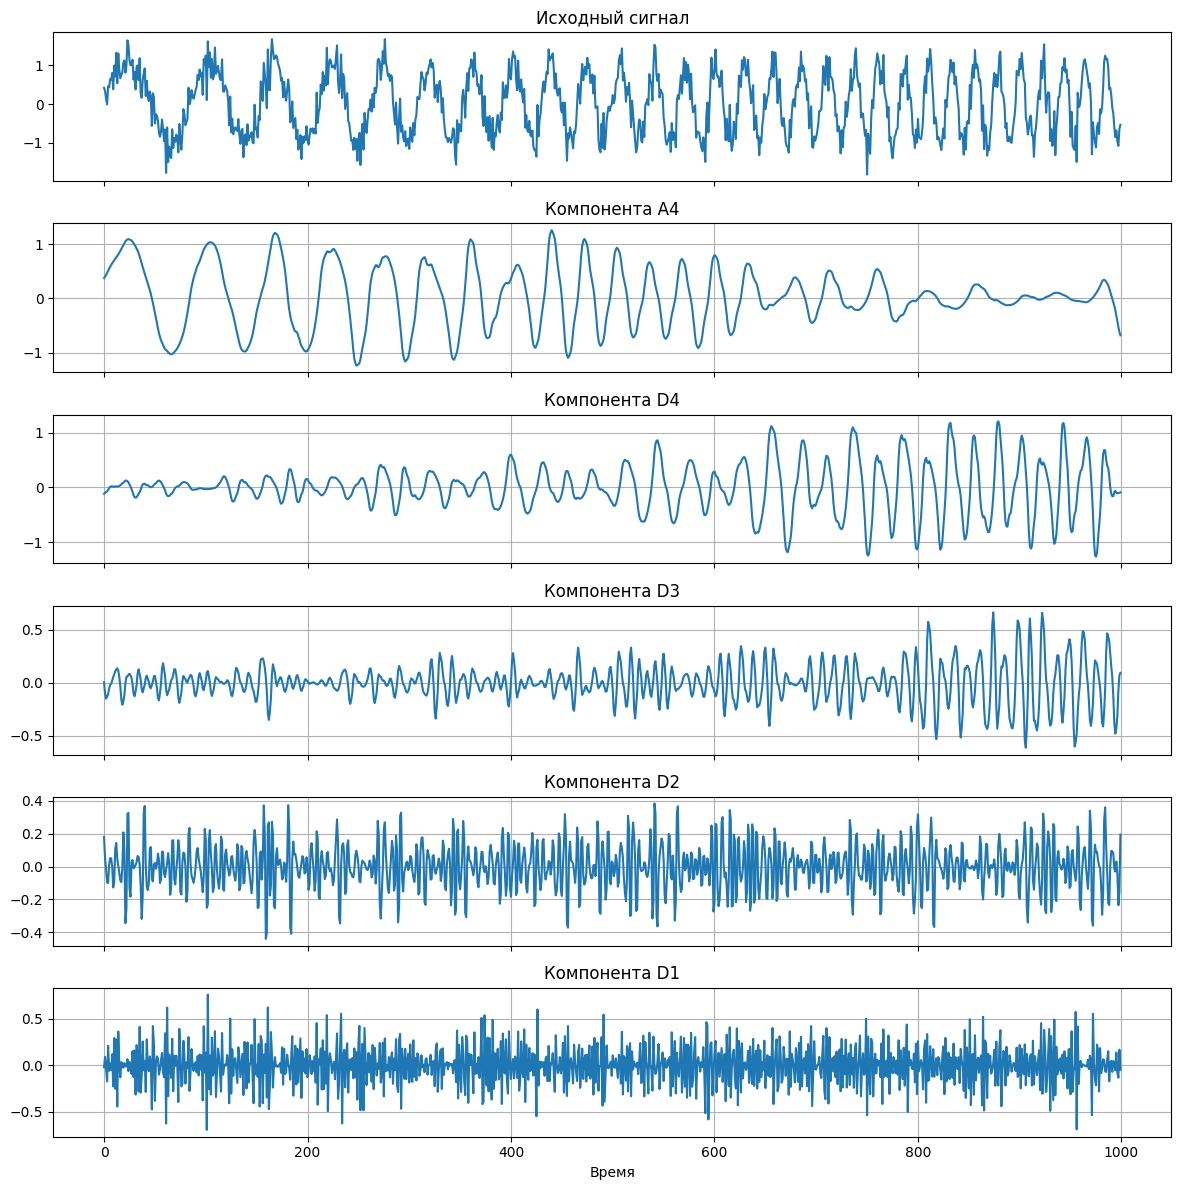

In [ ]:
components = []

for i, coeff in enumerate(coeffs):
    isolated = [
        np.zeros_like(c) for c in coeffs
    ]
    isolated[i] = coeff

    component = pywt.waverec(
        isolated,
        wavelet=wavelet
    )

    # waverec может вернуть ряд чуть длиннее исходного
    components.append(component[:len(y)])

names = ["A4", "D4", "D3", "D2", "D1"]

fig, axes = plt.subplots(
    len(components) + 1,
    1,
    figsize=(12, 12),
    sharex=True
)

axes[0].plot(y)
axes[0].set_title("Исходный сигнал")

for ax, component, name in zip(axes[1:], components, names):
    ax.plot(component)
    ax.set_title(f"Компонента {name}")
    ax.grid(True)

axes[-1].set_xlabel("Время")
plt.tight_layout()
plt.show()

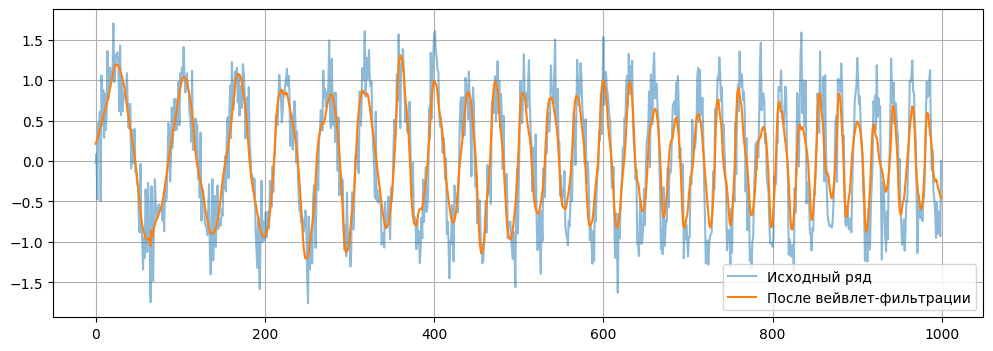

In [ ]:
# Оценка масштаба шума по самым мелким деталям
sigma = np.median(np.abs(coeffs[-1])) / 0.6745

# Универсальный порог
threshold = sigma * np.sqrt(2 * np.log(len(y)))

# Аппроксимацию оставляем, детали порогово обрабатываем
filtered_coeffs = [coeffs[0]]
filtered_coeffs += [
    pywt.threshold(c, value=threshold, mode="soft")
    for c in coeffs[1:]
]

y_denoised = pywt.waverec(
    filtered_coeffs,
    wavelet
)[:len(y)]

plt.figure(figsize=(12, 4))
plt.plot(y, label="Исходный ряд", alpha=0.5)
plt.plot(y_denoised, label="После вейвлет-фильтрации")
plt.legend()
plt.grid(True)
plt.show()

# EDA

In [ ]:
df = pd.read_excel('/content/Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
df['StockCode'].value_counts().head()

,count
StockCode,
85123A,2313
22423,2203
85099B,2159
47566,1727
20725,1639


In [ ]:
df['Quantity'].describe()

,Quantity
count,541909.000000
mean,9.552250
std,218.081158
min,-80995.000000
25%,1.000000
50%,3.000000
75%,10.000000
max,80995.000000


In [ ]:
df[df['StockCode'] == "85123A"]['Description'].value_counts()

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2302
CREAM HANGING HEART T-LIGHT HOLDER,9
?,1
wrongly marked carton 22804,1


In [ ]:
 df[(df['StockCode'] == "85123A")  & ~df['InvoiceNo'].astype('str').str.startswith('C')]['Description'].value_counts()

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2260
CREAM HANGING HEART T-LIGHT HOLDER,9
?,1
wrongly marked carton 22804,1


In [ ]:
 df[df['Description'].str.contains('hanging heart', case=False) == True]['Description'].value_counts()

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2369
RED HANGING HEART T-LIGHT HOLDER,773
HANGING HEART JAR T-LIGHT HOLDER,767
HANGING HEART ZINC T-LIGHT HOLDER,612
CANDLEHOLDER PINK HANGING HEART,416
HANGING HEART MIRROR DECORATION,303
HOME SWEET HOME HANGING HEART,240
HANGING HEART WITH BELL,229
HANGING HEART BONHEUR,79


In [ ]:
(
    df[(df['StockCode'] == "85123A")
       & ~df['InvoiceNo'].astype('str').str.startswith('C')
       & (df['Description'].str.contains('hanging heart', case=False) == True)]
      ['InvoiceDate'].dt.floor('D').nunique()
)

305

In [ ]:
sales = (
    df[(df['StockCode'] == "85123A")
       & ~df['InvoiceNo'].astype('str').str.startswith('C')
       & (df['Description'].str.contains('hanging heart', case=False) == True)]
      .set_index('InvoiceDate')[['Quantity']].resample('D').sum()
)
sales.shape

(374, 1)

In [ ]:
sales[sales['Quantity'] == 0].shape, 374 - 305

((69, 1), 69)

In [ ]:
sales['Quantity'].describe()

,Quantity
count,374.000000
mean,100.705882
std,223.735372
min,0.000000
25%,15.000000
50%,58.000000
75%,116.000000
max,3114.000000


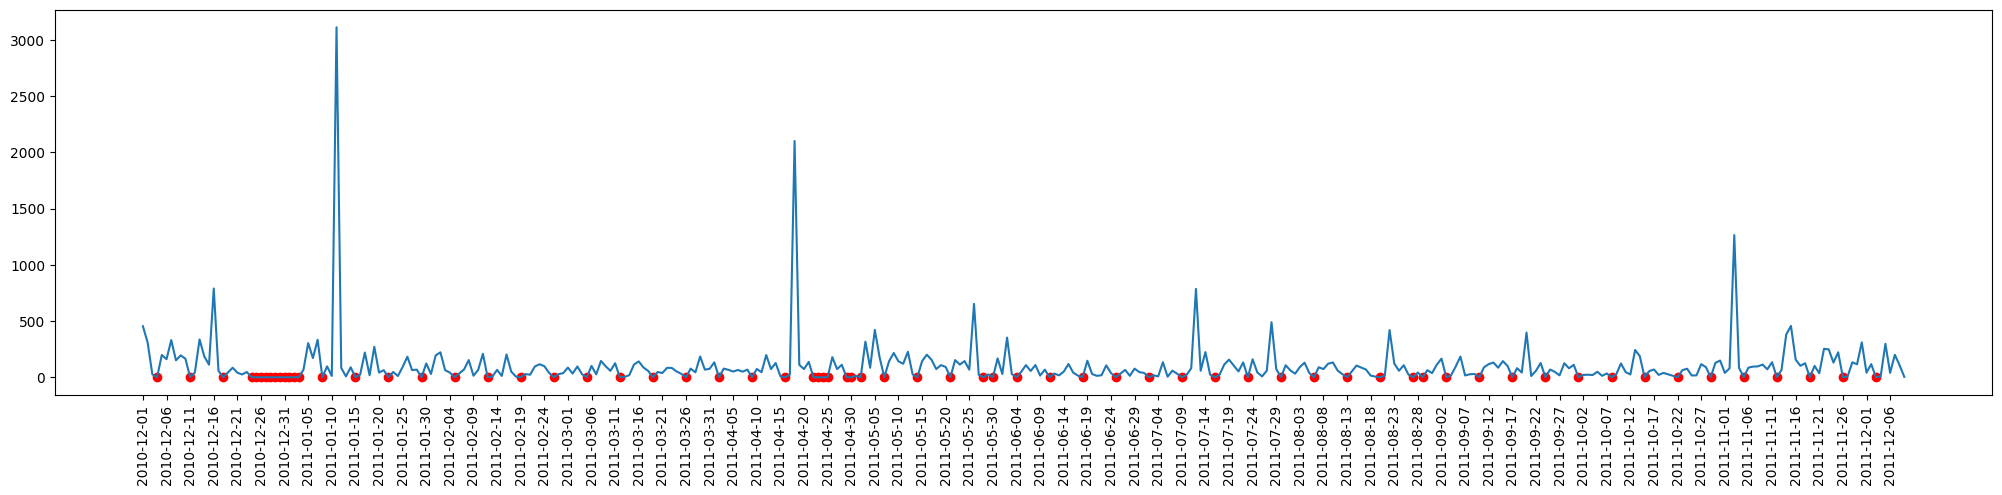

In [ ]:
plt.figure(figsize=(25,5))
plt.plot(sales.index, sales['Quantity'])
plt.scatter(sales[sales['Quantity'] == 0].index, sales[sales['Quantity'] == 0]['Quantity'], color='red')
plt.xticks(sales.index[::5], rotation=90)
plt.show()

In [ ]:
(sales['Quantity'] > 1000).sum()

np.int64(3)

In [ ]:
sales[(sales['Quantity'] < 1000)].max()

,0
Quantity,790


In [ ]:
sales['Quantity'] = sales['Quantity'].clip(0, sales[(sales['Quantity'] < 1000)].max()[0])
sales['Quantity'].describe()

/tmp/ipykernel_806/604220919.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sales['Quantity'] = sales['Quantity'].clip(0, sales[(sales['Quantity'] < 1000)].max()[0])


,Quantity
count,374.000000
mean,89.713904
std,122.648874
min,0.000000
25%,15.000000
50%,58.000000
75%,116.000000
max,790.000000


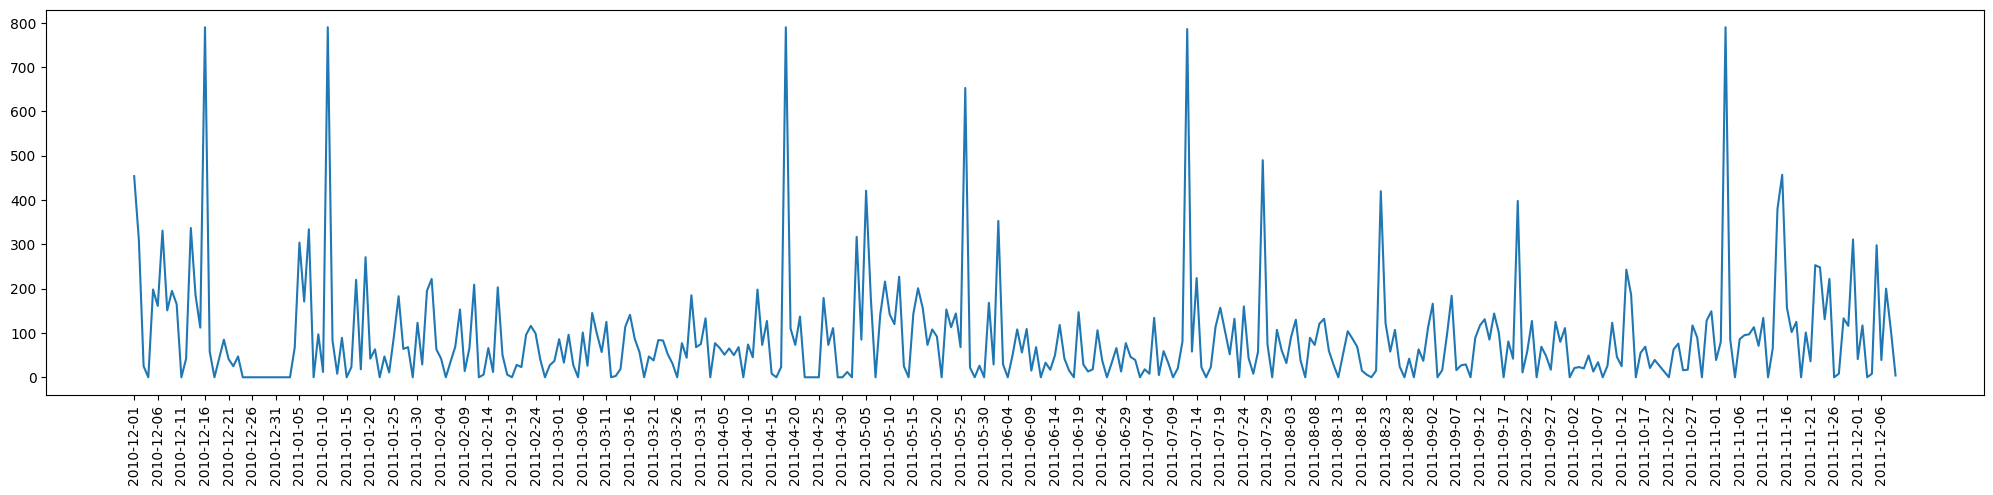

In [ ]:
plt.figure(figsize=(25,5))
plt.plot(sales.index, sales['Quantity'])
plt.xticks(sales.index[::5], rotation=90)
plt.show()

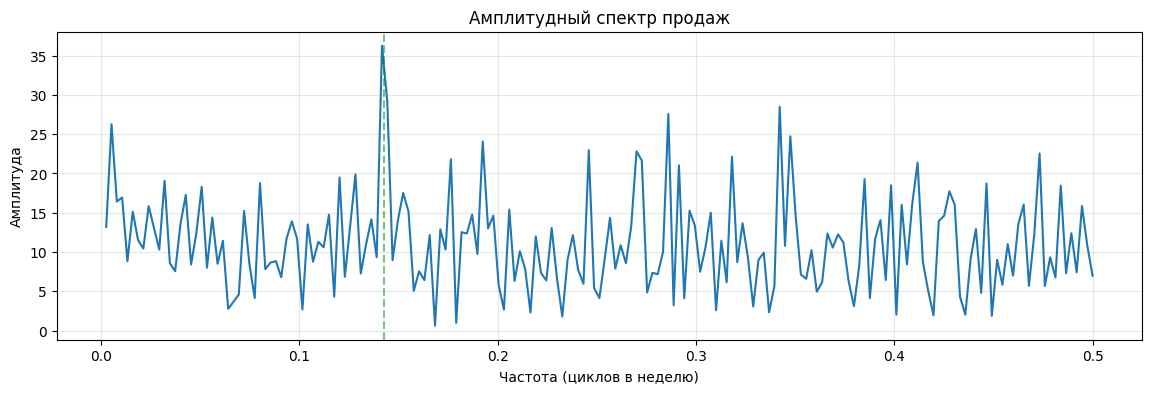

In [ ]:
n = len(sales)

y = sales['Quantity'].to_numpy(dtype=float)
y = y - y.mean()
spectrum = np.fft.rfft(y)

freqs = np.fft.rfftfreq(n, d=1)
amplitude = np.abs(spectrum) / n
if n % 2 == 0:
    amplitude[1:-1] *= 2
else:
    amplitude[1:] *= 2

plt.figure(figsize=(14, 4))
plt.plot(freqs[1:], amplitude[1:])
plt.axvline(1/7, ls='--', c='g', alpha=.5)
plt.xlabel("Частота (циклов в неделю)")
plt.ylabel("Амплитуда")
plt.title("Амплитудный спектр продаж")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
  1 / 7

0.14285714285714285

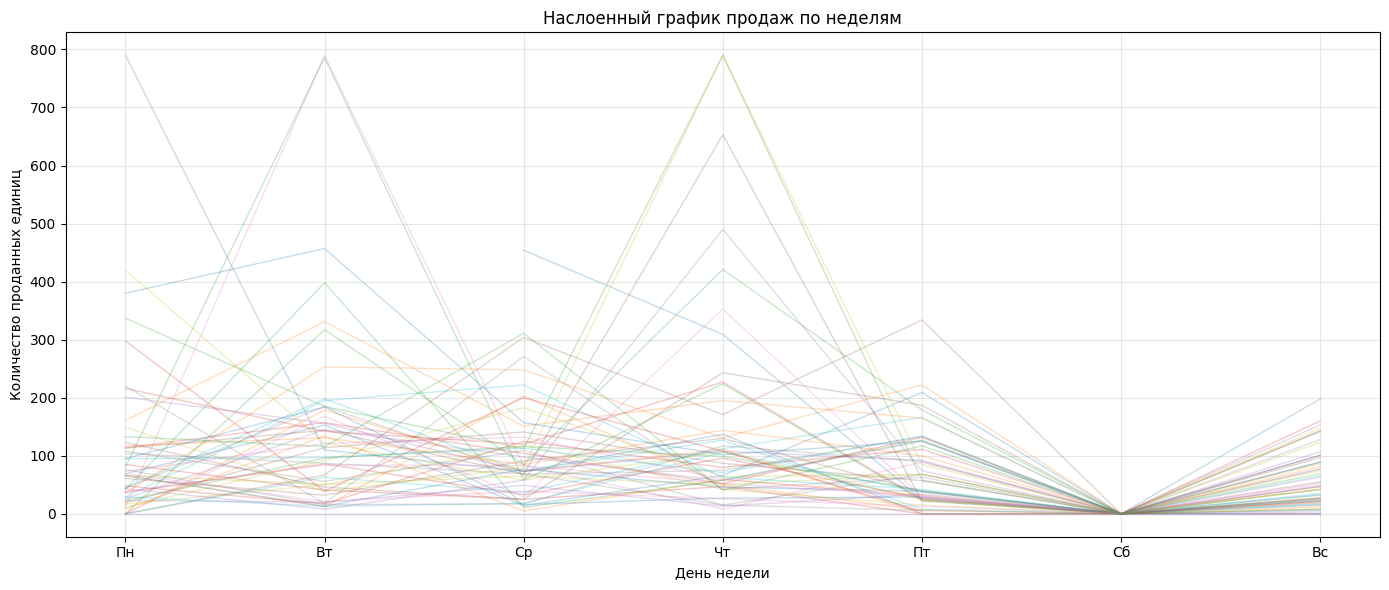

In [ ]:
s = sales["Quantity"].copy()

# Добавляем номер дня недели и дату начала недели
df_weekly = s.rename("sales").to_frame()
df_weekly["weekday"] = df_weekly.index.dayofweek
df_weekly["week_start"] = (
    df_weekly.index
    - pd.to_timedelta(df_weekly.index.dayofweek, unit="D")
)

# Превращаем данные в таблицу:
# строки — недели, столбцы — дни недели
weekly_pivot = df_weekly.pivot_table(
    index="week_start",
    columns="weekday",
    values="sales",
    aggfunc="sum"
)

# Сохраняем правильный порядок дней
days = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
weekly_pivot = weekly_pivot.reindex(columns=range(7))
weekly_pivot.columns = days

# Строим наслоенный график
plt.figure(figsize=(14, 6))

for week, row in weekly_pivot.iterrows():
    plt.plot(
        days,
        row.values,
        alpha=0.25,
        linewidth=1
    )

plt.xlabel("День недели")
plt.ylabel("Количество проданных единиц")
plt.title("Наслоенный график продаж по неделям")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

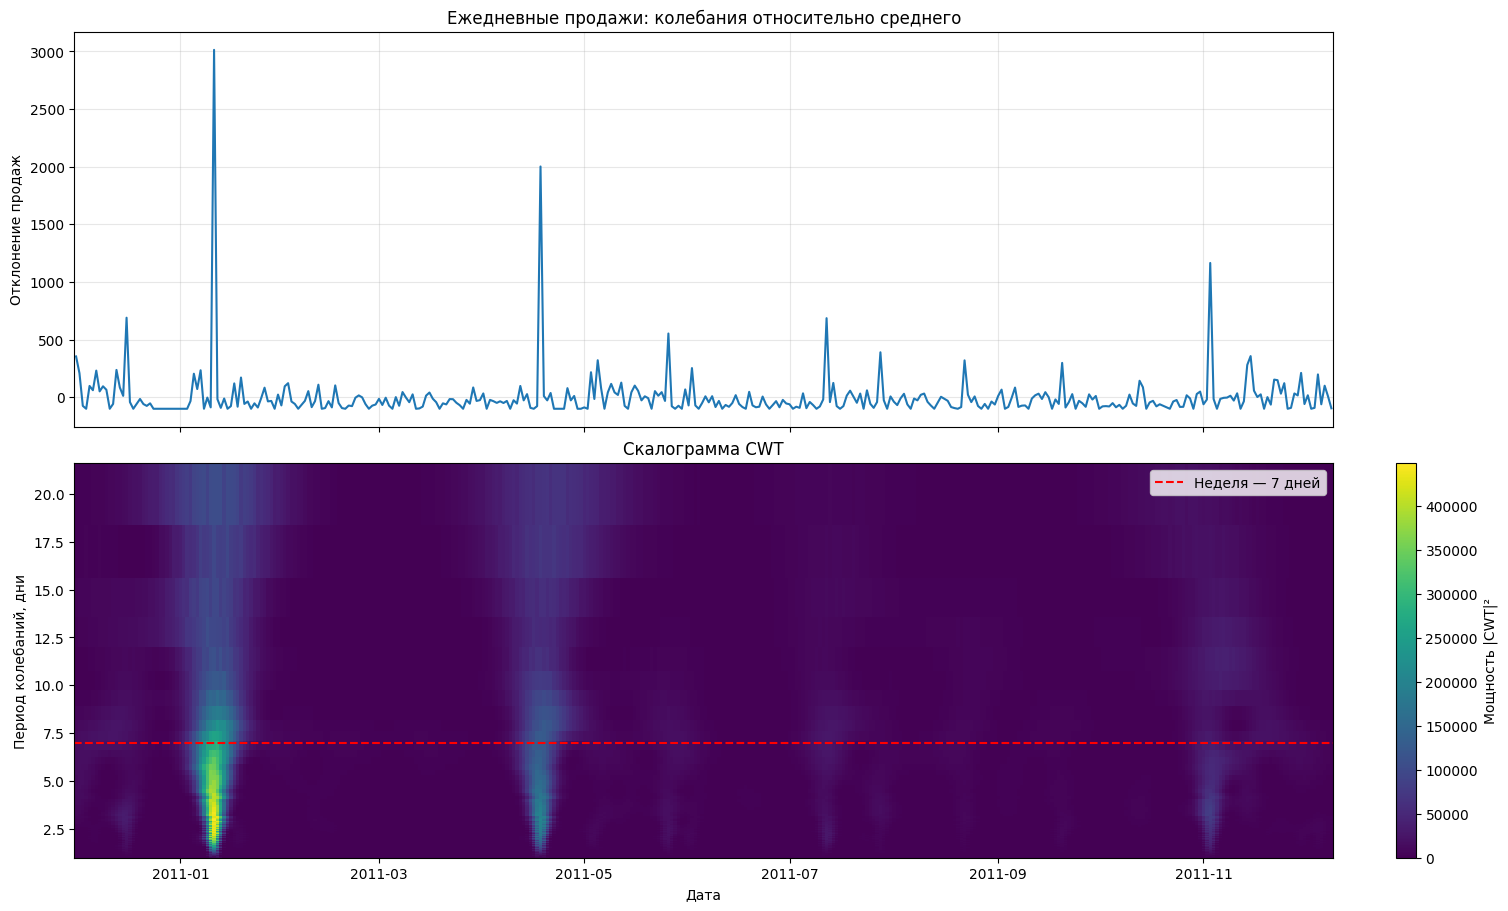

In [ ]:
y = sales["Quantity"].to_numpy(dtype=float)

# Если в ряду есть пропуски, заменим их нулями.
# Это подходит, если пропуски означают отсутствие продаж.
y = np.nan_to_num(y, nan=0.0)

# Уберём средний уровень
y = y - y.mean()

# Зададим масштабы, соответствующие разным периодам
wavelet = "cmor1.5-1.0"
target_freqs = np.linspace(1/20, 1, 100)
scales = pywt.frequency2scale(wavelet, target_freqs)

# Рассчитаем CWT
coefficients, frequencies = pywt.cwt(
    y,
    scales,
    wavelet,
    sampling_period=1  # один отсчёт = один день
)

# Переведём частоты в периоды (дни)
periods = 1 / frequencies

# Построим скалограмму
power = np.abs(coefficients) ** 2

fig, axes = plt.subplots(
    2, 1, figsize=(15, 9),
    sharex=True,
    layout="constrained"
)

# Исходный ряд
axes[0].plot(sales.index, y)
axes[0].set_title("Ежедневные продажи: колебания относительно среднего")
axes[0].set_ylabel("Отклонение продаж")
axes[0].grid(alpha=0.3)

# Скалограмма: цвет показывает мощность колебаний
mesh = axes[1].pcolormesh(
    sales.index,
    periods,
    power,
    shading="auto",
    cmap="viridis"
)

# axes[1].set_yscale("log")
# axes[1].set_ylim(2, 64)
axes[1].set_title("Скалограмма CWT")
axes[1].set_ylabel("Период колебаний, дни")
axes[1].set_xlabel("Дата")
axes[1].axhline(7, color="red", linestyle="--",
                linewidth=1.5, label="Неделя — 7 дней")
axes[1].legend()

fig.colorbar(mesh, ax=axes[1], label="Мощность |CWT|²")
plt.show()


In [ ]:
sales.nlargest(10, "Quantity")

,Quantity
InvoiceDate,
2010-12-16,790
2011-01-11,790
2011-04-18,790
2011-11-03,790
2011-07-12,786
2011-05-26,653
2011-07-28,490
2011-11-15,457
2010-12-01,454


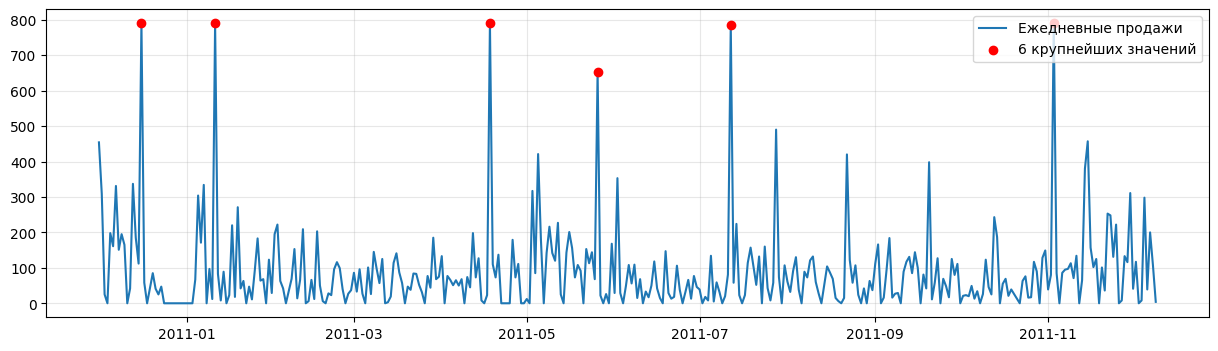

In [ ]:
y = sales["Quantity"]

plt.figure(figsize=(15, 4))
plt.plot(sales.index, y, label="Ежедневные продажи")

top = sales.nlargest(6, "Quantity")
plt.scatter(
    top.index,
    top["Quantity"],
    color="red",
    zorder=3,
    label="6 крупнейших значений"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

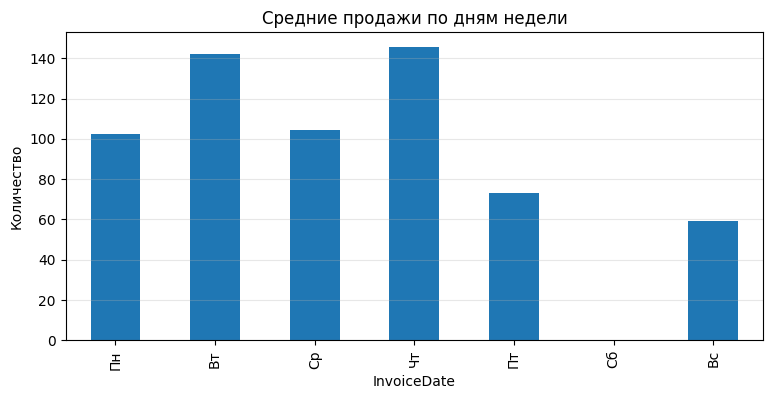

In [ ]:
sales["Quantity"].groupby(
    sales.index.dayofweek
).mean().rename({
    0: "Пн", 1: "Вт", 2: "Ср", 3: "Чт",
    4: "Пт", 5: "Сб", 6: "Вс"
}).plot(kind="bar", figsize=(9, 4))

plt.title("Средние продажи по дням недели")
plt.ylabel("Количество")
plt.grid(axis="y", alpha=0.3)
plt.show()

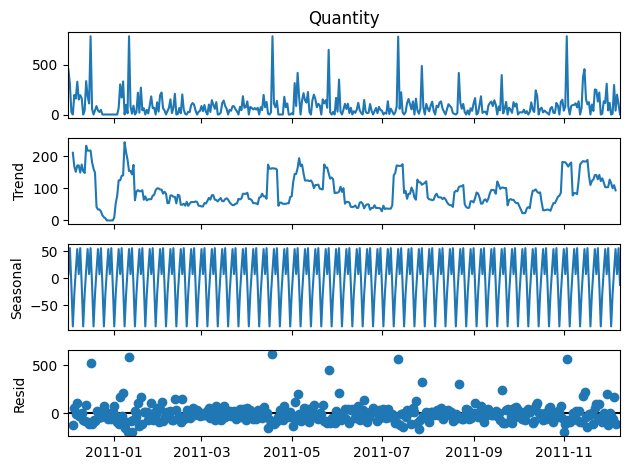

In [ ]:
seasonal_decompose(sales["Quantity"],
                   model='additive',
                   period=7).plot()
plt.show()

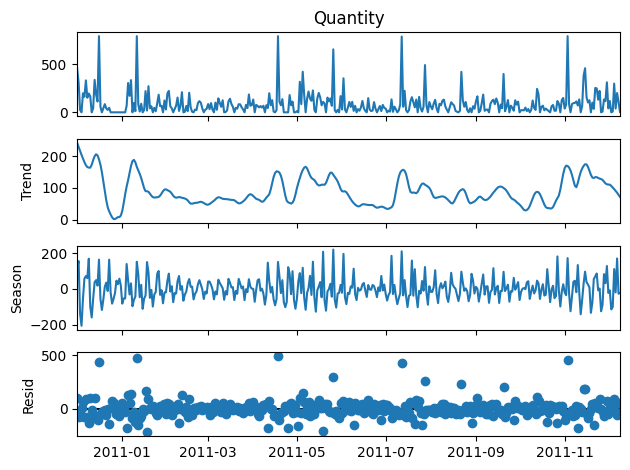

In [ ]:
STL(sales["Quantity"], seasonal=7).fit().plot()
plt.show()

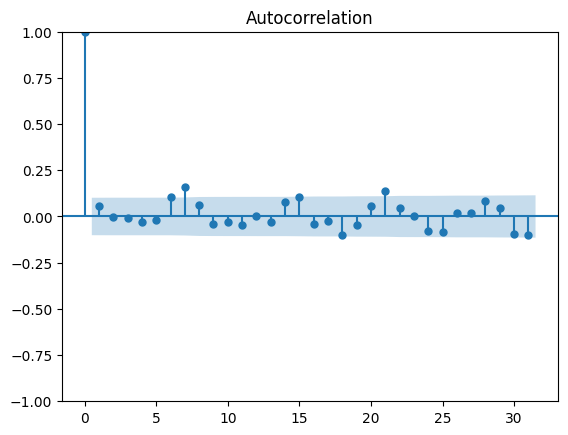

In [ ]:
plot_acf(sales["Quantity"], lags=31)
plt.show()

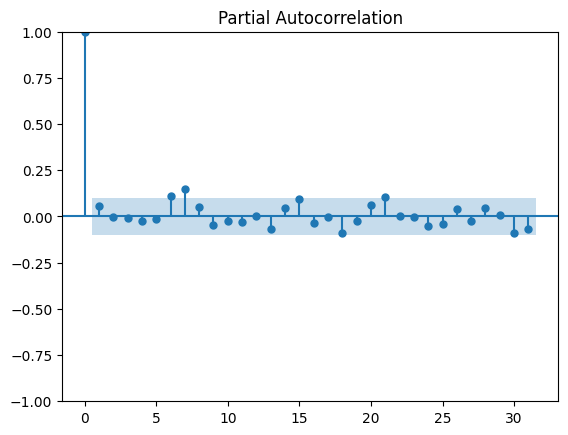

In [ ]:
plot_pacf(sales["Quantity"], lags=31)
plt.show()

<center>$CI=\pm \frac{1.96}{\sqrt{N}}$</center>

In [ ]:
autocorr = acf(sales["Quantity"], nlags=52/2, fft=True)
pautocorr = pacf(sales["Quantity"], nlags=52/2)

for lag in [1, 2, 6, 7, 8]:
    print(f"Lag {lag}: {autocorr[lag]:.3f}, {pautocorr[lag]:.3f}")

Lag 1: 0.055, 0.056
Lag 2: -0.001, -0.004
Lag 6: 0.107, 0.111
Lag 7: 0.160, 0.152
Lag 8: 0.064, 0.051


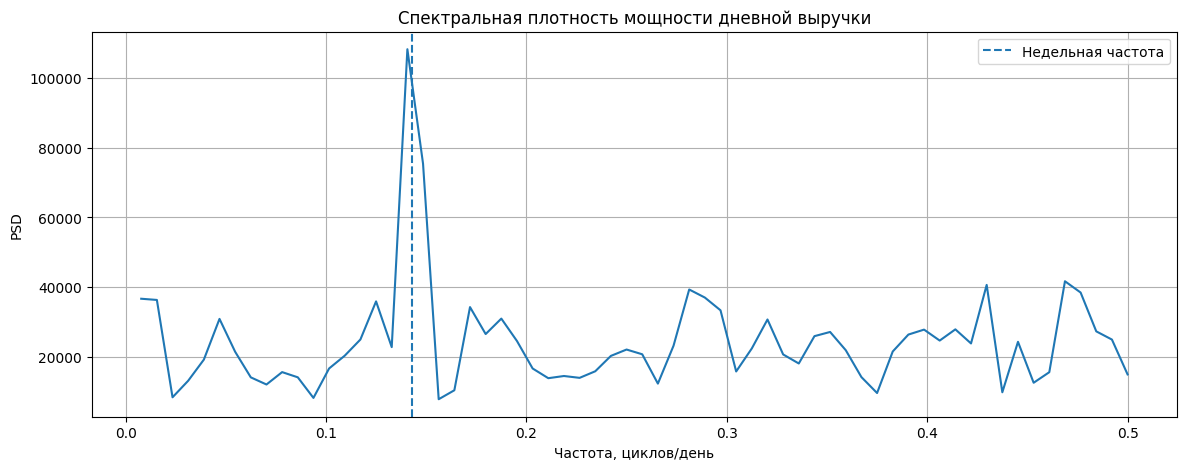

In [ ]:
# PSD - Power Spectral Density

y = sales["Quantity"].to_numpy(dtype=float)
y = y - y.mean()

freqs, psd = welch(
    y,
    fs=1.0,              # один отсчёт в день
    detrend="constant",
    nperseg=128, # каждый отрезок содержит до 128 дней
    noverlap=64, # соседние отрезки перекрываются на 64 дня
)

plt.figure(figsize=(14, 5))
plt.plot(freqs[1:], psd[1:])
plt.axvline(1 / 7, linestyle="--", label="Недельная частота")
plt.xlabel("Частота, циклов/день")
plt.ylabel("PSD")
plt.title("Спектральная плотность мощности дневной выручки")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# центр тяжести по мощности
freqs = np.fft.rfftfreq(len(y), d=1)
power = np.abs(np.fft.rfft(y)) ** 2

freqs = freqs[1:]
power = power[1:]

centroid = np.sum(freqs * power) / np.sum(power)

print("Центр тяжести:", centroid)

Центр тяжести: 0.2514486949341298


In [ ]:
# центр тяжести по амплитуде
freqs = np.fft.rfftfreq(len(y), d=1)
amplitude = np.abs(np.fft.rfft(y))

freqs = freqs[1:]
amplitude = amplitude[1:] * 2

centroid = np.sum(freqs * amplitude) / np.sum(amplitude)

print("Центр тяжести:", centroid)

Центр тяжести: 0.25151510115707887


In [ ]:
1/7, 2/7

(0.14285714285714285, 0.2857142857142857)

In [ ]:
# энтропия
power = np.abs(np.fft.rfft(y)) ** 2
power = power[1:]  # исключаем нулевую частоту

p = power / power.sum()
p = p[p > 0]

# энтропия Шеннона
entropy = -np.sum(p * np.log(p))
entropy_norm = entropy / np.log(len(power))

# Низкая энтропия — мощность сосредоточена на нескольких частотах.
# Высокая энтропия — мощность распределена по многим частотам относительно равномерно.
print("Cпектральная энтропия:", entropy)
print("Нормированная спектральная энтропия:", entropy_norm)

Cпектральная энтропия: 4.887989261475756
Нормированная спектральная энтропия: 0.9344079084358327


##